# Análisis Exploratorio de Datos (EDA)


### **Resumen:**

Este conjunto de datos contiene registros etiquetados de captura de movimiento y electromiografía de superficie (sEMG), adquiridos en un laboratorio bajo condiciones controladas. Está orientado al análisis biomecánico, la ergonomía y los modelos de aprendizaje automático que estiman torques articulares, pesos de carga o la cinética del movimiento. El objetivo de este notebook es realizar un Análisis Exploratorio de Datos (EDA) para comprender la estructura y el contenido del conjunto. Esta segunda versión amplía el análisis de captura de movimiento con la revisión de integridad de los archivos, sus etiquetas MVNX, las características del movimiento y su relación con sEMG.

**Contenido de `datos_unzipped/`** (conjunto human-activity-recognition, 14 sujetos)

* `Data/` (10 GB, 679 CSV): registros de electromiografía de superficie, con una carpeta por sujeto y un CSV por ensayo (~690 Hz). Columnas: `Time`, `Raw_V_1..8` (voltaje crudo), `Norm_V_1..8` (señal rectificada, %MVC) y `Norm_RMS_1..8` (envolvente RMS de 250 ms, %MVC). Los nombres de archivo codifican el sujeto, la tarea (`Isokin`, `MMH_Bim`, `MMH_One`, `MVC_*`), el lado (L/R), la carga (kg) y la condición (bpm, `St` para estático o número de ensayo).
* `Labels/` (679 CSV): un archivo por registro EMG de la carpeta anterior. Los ensayos regulares contienen segmentos `Start_Frame`, `End_Frame`, `Label` con siete clases de actividad (N, LF, K, PT, LT, W, PF). Los archivos MVC (`*_range.csv`) solo indican el intervalo de muestras usado para calcular el valor de referencia MVC.
* `mvnx_files/` (56 GB, 517 archivos): captura de movimiento de cuerpo completo con Xsens MVN (XML, 240 Hz, 23 segmentos), con 36–37 archivos por sujeto y sin registros MVC. Los ensayos bimanuales comparten un único archivo entre los registros EMG de los lados L/R.
* `Labels 2/` (517 CSV): segmentos de actividad indexados sobre la grabación MVNX, con un archivo de etiquetas por ensayo de captura de movimiento.
* `Subjs_info.xlsx`: tabla demográfica y antropométrica de los 14 sujetos (12 hombres, 2 mujeres, de 25 a 38 años).
* `m_files/`: scripts de preprocesamiento en MATLAB (filtro de rechazo a 50 Hz, filtro pasa banda de 20 Hz a Nyquist, media móvil de 2 muestras, rectificación, normalización MVC y envolvente RMS de 250 ms) que generaron las columnas normalizadas.

**Contenido:**

1. Configuración
2. Inventario de archivos
3. Participantes
4. Registros sEMG
5. Etiquetas de actividad
6. Calidad de la señal sEMG
7. Ensayos de ejemplo
8. sEMG y actividad
9. Captura de movimiento (MVNX)
10. Resumen de hallazgos
11. Glosario

*Fuentes:*

- *Datos: https://zenodo.org/records/4633087*
- *Artículo: G. Bassani, A. Filippeschi, C. A. Avizzano, "A Dataset of Human Motion and Muscular Activities in Manual Material Handling Tasks for Biomechanical and Ergonomic Analyses", IEEE Sensors Journal, vol. 21, núm. 21, 2021. https://ieeexplore.ieee.org/document/9539228*


# 1. Configuración

Dependencias: `numpy`, `pandas`, `matplotlib` y `openpyxl` (para leer `Subjs_info.xlsx`).

Los dos recorridos extensos de los 10 GB de CSV sEMG (secciones 4 y 6) guardan sus resultados en `notebooks/_cache/`. Usa `REFRESH = True` para recalcularlos.

La sección 9 usa el analizador XML de la biblioteca estándar (`xml.etree.ElementTree`) y lee los archivos MVNX de uno en uno. El recorrido completo de ~57 GB también se guarda en caché, en `notebooks/_cache/mvnx_v2/`. Esta caché se reconstruye si cambia un archivo de señales o de etiquetas; `REFRESH = True` fuerza todos los recorridos. No se necesitan paquetes adicionales.


In [1]:
import re                        # Interpretar los nombres de archivo
import json                      # Registro de archivos de origen para la caché MVNX
import hashlib                   # Comparar las definiciones del modelo corporal y los campos MVNX
import xml.etree.ElementTree as ET # Leer secuencialmente los archivos MVNX (XML)
import time                      # Medir la duración de los recorridos extensos
from itertools import product    # Productos cartesianos: ensayos esperados y celdas de mapas de calor
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

## Definir el máximo de columnas y el ancho de las tablas mostradas
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 160)

## Configurar el estilo de las gráficas de matplotlib
plt.rcParams.update({
    "figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3,
    "axes.spines.top": False, "axes.spines.right": False,
})

In [2]:
## Rutas: el notebook está en notebooks/ y los datos extraídos en datos_unzipped/
PROJECT_DIR = Path.cwd().resolve()
if not (PROJECT_DIR / "datos_unzipped").is_dir():
    PROJECT_DIR = PROJECT_DIR.parent    # Permitir también la ejecución desde notebooks/
ROOT = PROJECT_DIR / "datos_unzipped"
EMG_DIR, LABEL_DIR, MVNX_DIR = ROOT / "Data", ROOT / "Labels", ROOT / "mvnx_files"
MVNX_LABEL_DIR = ROOT / "Labels 2"
SUBJ_XLSX = ROOT.parent / "datos" / "Subjs_info.xlsx"    # Este archivo permanece en datos/, fuera de datos_unzipped/

## Crear _cache para guardar resultados intermedios
CACHE_DIR = PROJECT_DIR / "notebooks" / "_cache"
CACHE_DIR.mkdir(exist_ok=True) # Si la carpeta ya existe, conservarla
REFRESH = False    # True = ignorar la caché de _cache/ y recalcular los recorridos (lento)

# Detectar rutas faltantes al inicio; normalmente indican una carpeta de trabajo incorrecta
for d in (EMG_DIR, LABEL_DIR, MVNX_DIR, MVNX_LABEL_DIR, SUBJ_XLSX):
    assert d.exists(), f"No se encontró: {d} (abre el notebook desde la raíz del proyecto o desde notebooks/)"

## Columnas sEMG
N_CH = 8
RAW = [f"Raw_V_{i}" for i in range(1, N_CH + 1)]         # Voltaje crudo [V]
NORM_V = [f"Norm_V_{i}" for i in range(1, N_CH + 1)]     # Señal rectificada, %MVC
NORM_RMS = [f"Norm_RMS_{i}" for i in range(1, N_CH + 1)] # Envolvente RMS de 250 ms, %MVC

## Etiquetas de actividad: definiciones de Bassani et al. usadas en la literatura HAR de este conjunto
LABELS = {
    "N": "Postura N", 
    "LF": "Levantar desde el suelo", 
    "K": "Mantener el objeto levantado", 
    "PT": "Colocar en la mesa",
    "LT": "Levantar desde la mesa", 
    "W": "Caminar / transportar",
    "PF": "Colocar en el suelo",
}
LABEL_ORDER = list(LABELS)    # Orden de clases utilizado en todas las tablas y gráficas
# Un color fijo por clase, compartido por todas las gráficas
LABEL_COLORS = dict(zip(LABEL_ORDER, ["#9e9e9e", "#1f77b4", "#ff7f0e", "#2ca02c", "#d62728", "#9467bd", "#8c564b"]))

# 2. Inventario de archivos

`datos_unzipped/` contiene las señales y sus anotaciones, que comparten la misma nomenclatura de ensayo:

| Carpeta | Contenido | Formato |
|---|---|---|
| `Data/Subj_XX/` | sEMG, 8 canales, un CSV por ensayo | CSV |
| `Labels/Subj_XX/` | Segmentos de actividad (`*_EMG_labels.csv`) o ventana MVC (`*_EMG_range.csv`) | CSV |
| `Labels 2/Subj_XX/` | Segmentos de actividad (`*_mvnx_labels.csv`), indexados sobre la captura de movimiento | CSV |
| `mvnx_files/Subj_XX/` | Captura de movimiento de cuerpo completo con Xsens, un archivo por ensayo | MVNX (XML) |
| `Subjs_info.xlsx` | Antropometría de los 14 participantes | XLSX |
| `m_files/` | Scripts MATLAB de los autores para filtrar y normalizar la sEMG | `.m` |

La identidad del ensayo está codificada en el nombre del archivo; el primer paso es extraerla y organizarla en una tabla.


In [3]:
# Patrones de nombres; parse_files lee los grupos (?P<...>) con groupdict()
# Ensayo sEMG: Subj_03_Isokin_L_04kg_60bpm_EMG_data.csv; MVC: Subj_02_MVC_All_L_EMG_data.csv
# Los bloques opcionales (?:...)? permiten reconocer ambos casos; MVC no tiene carga ni condición
EMG_RE = re.compile(
    r"Subj_(?P<subject>\d+)_(?:(?P<mvc>MVC)_)?(?P<task>Isokin|MMH_Bim|MMH_One|All)_(?P<side>[LR])"
    r"(?:_(?P<load_kg>\d+)kg_(?P<condition>St|\d+bpm|Trial_\d))?_EMG_data\.csv"
)
# Captura: Subj_03_MMH_Bim_08kg_Trial_2.mvnx; el lado es opcional porque los bimanuales no lo incluyen
MVNX_RE = re.compile(
    r"Subj_(?P<subject>\d+)_(?P<task>Isokin|MMH_Bim|MMH_One)(?:_(?P<side>[LR]))?"
    r"_(?P<load_kg>\d+)kg_(?P<condition>St|\d+bpm|Trial_\d)\.mvnx"
)


def parse_files(paths, regex):
    # Una fila por archivo; extraer sujeto, tarea, lado, carga y condición del nombre
    rows = []
    for p in paths:
        m = regex.fullmatch(p.name)    # Debe coincidir el nombre completo; de lo contrario, informar el error
        if m is None:
            raise ValueError(f"Nombre de archivo no reconocido: {p.name}")
        d = m.groupdict()
        rows.append(dict(
            file=p.name, path=p, subject=int(d["subject"]), task=d["task"], side=d["side"],
            is_mvc=d.get("mvc") is not None,    # Solo EMG_RE tiene el grupo "mvc"; por eso se usa .get
            # side es None en MVNX bimanual y load_kg es NaN en MVC
            load_kg=float(d["load_kg"]) if d["load_kg"] else np.nan, condition=d["condition"],
        ))
    return pd.DataFrame(rows)


# Inventario sEMG ordenado para reproducir el orden de las filas
emg = parse_files(sorted(EMG_DIR.glob("Subj_*/*.csv")), EMG_RE)
# key es el nombre sin sufijo y relaciona la señal sEMG con su archivo de etiquetas
emg["key"] = emg.file.str.replace("_EMG_data.csv", "", regex=False)
# Etiquetas: *_labels.csv para ensayos y *_range.csv para la ventana MVC
emg["label_path"] = [
    LABEL_DIR / f"Subj_{s:02d}" / f"{k}_EMG_{'range' if mvc else 'labels'}.csv"
    for s, k, mvc in zip(emg.subject, emg.key, emg.is_mvc)
]
# Inventario de archivos de captura de movimiento
mocap = parse_files(sorted(MVNX_DIR.glob("Subj_*/*.mvnx")), MVNX_RE)

print(f"Archivos sEMG: {len(emg)} ({(~emg.is_mvc).sum()} ensayos + {emg.is_mvc.sum()} MVC)")
# Cada archivo sEMG debe tener su archivo de etiquetas
print(f"Archivos de etiquetas con un registro sEMG correspondiente: {emg.label_path.map(Path.exists).sum()} / {len(emg)}")
print(f"Archivos MVNX: {len(mocap)}")

Archivos sEMG: 679 (643 ensayos + 36 MVC)
Archivos de etiquetas con un registro sEMG correspondiente: 679 / 679
Archivos MVNX: 517


In [4]:
## Ejemplo:
## Data/ contiene 14 subcarpetas de registros sEMG, una por sujeto
display(emg.head(5))

,file,path,subject,task,side,is_mvc,load_kg,condition,key,label_path
0,Subj_01_Isokin_L_02kg_40bpm_EMG_data.csv,E:\Proyecto_Integrador\human-activity-recognit...,1,Isokin,L,False,2.0,40bpm,Subj_01_Isokin_L_02kg_40bpm,E:\Proyecto_Integrador\human-activity-recognit...
1,Subj_01_Isokin_L_02kg_60bpm_EMG_data.csv,E:\Proyecto_Integrador\human-activity-recognit...,1,Isokin,L,False,2.0,60bpm,Subj_01_Isokin_L_02kg_60bpm,E:\Proyecto_Integrador\human-activity-recognit...
2,Subj_01_Isokin_L_02kg_80bpm_EMG_data.csv,E:\Proyecto_Integrador\human-activity-recognit...,1,Isokin,L,False,2.0,80bpm,Subj_01_Isokin_L_02kg_80bpm,E:\Proyecto_Integrador\human-activity-recognit...
3,Subj_01_Isokin_L_02kg_St_EMG_data.csv,E:\Proyecto_Integrador\human-activity-recognit...,1,Isokin,L,False,2.0,St,Subj_01_Isokin_L_02kg_St,E:\Proyecto_Integrador\human-activity-recognit...
4,Subj_01_Isokin_L_04kg_40bpm_EMG_data.csv,E:\Proyecto_Integrador\human-activity-recognit...,1,Isokin,L,False,4.0,40bpm,Subj_01_Isokin_L_04kg_40bpm,E:\Proyecto_Integrador\human-activity-recognit...


### Diseño experimental e integridad del inventario

Cada sujeto realiza 37 ensayos en el sistema de captura de movimiento:

- **Isocinéticos (`Isokin`)**: un brazo (`L`/`R`), cargas de 2 y 4 kg, condición estática (`St`) y 40/60/80 bpm → 16 ensayos.
- **MMH bimanual (`MMH_Bim`)**: cargas de 2, 8 y 12 kg × 3 ensayos → 9 ensayos. La sEMG se registra en ambos brazos, por lo que existe un archivo sEMG `Bim_L` y otro `Bim_R` por ensayo, pero un único MVNX.
- **MMH unilateral (`MMH_One`)**: `L`/`R`, cargas de 2 y 4 kg × 3 ensayos → 12 ensayos.

Con este diseño podemos construir la lista de ensayos esperados y comprobar cuáles faltan.


In [5]:
# Ensayos esperados según el diseño experimental, para detectar archivos faltantes
def expected_trials(with_side_for_bim):
    # with_side_for_bim: sEMG tiene Bim_L y Bim_R; MVNX tiene un solo archivo con side = None
    rows = []
    # Isocinéticos: 2 lados x 2 cargas x (estático + 3 frecuencias de metrónomo)
    for side, load, cond in product("LR", (2, 4), ("St", "40bpm", "60bpm", "80bpm")):
        rows.append(("Isokin", side, load, cond))
    # MMH bimanual: (2 lados o ninguno) x 3 cargas x 3 ensayos
    for side, load, t in product("LR" if with_side_for_bim else [None], (2, 8, 12), (1, 2, 3)):
        rows.append(("MMH_Bim", side, load, f"Trial_{t}"))
    # MMH unilateral: 2 lados x 2 cargas x 3 ensayos
    for side, load, t in product("LR", (2, 4), (1, 2, 3)):
        rows.append(("MMH_One", side, load, f"Trial_{t}"))
    exp = pd.DataFrame(rows, columns=["task", "side", "load_kg", "condition"])
    exp["load_kg"] = exp.load_kg.astype(float)    # Usar el mismo tipo de dato que parse_files para combinar las tablas
    # Repetir el diseño para cada uno de los 14 sujetos
    return pd.concat([exp.assign(subject=s) for s in range(1, 15)], ignore_index=True)


# Unión izquierda de esperados con encontrados: "left_only" identifica archivos faltantes
def find_missing(found, expected):
    keys = ["subject", "task", "side", "load_kg", "condition"]
    merged = expected.merge(found[keys], on=keys, how="left", indicator=True)
    return merged[merged._merge == "left_only"].drop(columns="_merge")


print("Ensayos sEMG faltantes:")
print(find_missing(emg[~emg.is_mvc], expected_trials(True)).to_string(index=False))
print("\nEnsayos MVNX faltantes:")
print(find_missing(mocap, expected_trials(False)).to_string(index=False))

Ensayos sEMG faltantes:
  task side  load_kg condition  subject
Isokin    L      2.0     80bpm       12

Ensayos MVNX faltantes:
  task side  load_kg condition  subject
Isokin    L      2.0     80bpm       12


In [6]:
## Archivos por sujeto y tarea: ensayos sEMG, MVC y MVNX
summary = pd.concat({
    "Ensayos sEMG": emg[~emg.is_mvc].groupby(["subject", "task"]).size().unstack(fill_value=0),
    "MVC sEMG": emg[emg.is_mvc].groupby("subject").size().rename("MVC").to_frame(),
    "MVNX": mocap.groupby("subject").size().rename("MVNX").to_frame(),
}, axis=1)
summary

Ensayos sEMG                 MVC sEMG MVNX
              Isokin MMH_Bim MMH_One      MVC MVNX
subject                                           
1                 16      18      12        6   37
2                 16      18      12        2   37
3                 16      18      12        2   37
4                 16      18      12        2   37
5                 16      18      12        2   37
6                 16      18      12        2   37
7                 16      18      12        2   37
8                 16      18      12        2   37
9                 16      18      12        2   37
10                16      18      12        2   37
11                16      18      12        6   37
12                15      18      12        2   36
13                16      18      12        2   37
14                16      18      12        2   37

Los archivos MVC (contracción voluntaria máxima) proporcionan la referencia para normalizar la sEMG a %MVC. Los sujetos 1 y 11 tienen un registro MVC por tarea (`Isokin`, `MMH_Bim`, `MMH_One`, para cada lado); los demás tienen un único registro `All` por lado.


# 3. Participantes


In [7]:
# Una fila por sujeto (ID 1–14), con datos demográficos y medidas corporales
subj = pd.read_excel(SUBJ_XLSX).set_index("ID")

## Ejemplo de la tabla de información de participantes:
display(subj.head(5))

print(subj.Sex.value_counts().to_dict())
# Media, desviación estándar, mínimo, mediana y máximo de cada columna numérica
subj.describe().T[["mean", "std", "min", "50%", "max"]].round(1)

,Sex,Age,Body_mass,Body_height,Foot_length,Shoulder_height,Shoulder_width,Elbow_span,Wrist_span,Arm_span,Hip_height,Hip_width,Knee_height,Ankle_height,Extra_shoe_thickeness
ID,,,,,,,,,,,,,,,
1,M,38,70,181,29.5,151.0,44,93.7,142.8,182,106.0,34.0,52.0,10,1
2,M,37,79,184,30.0,156.0,39,95.0,141.0,183,103.0,37.0,59.0,13,3
3,F,35,58,166,26.0,140.0,38,83.0,122.0,161,97.0,28.0,52.0,14,8
4,M,28,78,187,32.0,152.0,41,96.0,146.0,186,100.0,34.0,52.0,14,3
5,M,25,72,180,30.0,154.0,45,89.0,144.0,180,105.0,33.0,54.0,13,1


{'M': 12, 'F': 2}


,mean,std,min,50%,max
Age,30.6,4.6,25.0,28.0,38.0
Body_mass,71.6,7.8,58.0,72.0,90.0
Body_height,178.6,5.4,166.0,179.0,187.0
Foot_length,29.3,1.8,25.0,29.8,32.0
Shoulder_height,148.7,5.0,140.0,148.5,156.0
Shoulder_width,41.6,3.9,32.0,42.0,46.0
Elbow_span,88.8,5.9,76.0,90.5,96.0
Wrist_span,133.8,13.2,103.0,140.5,148.0
Arm_span,176.6,8.6,161.0,177.5,188.0
Hip_height,101.3,3.8,96.0,100.9,108.0


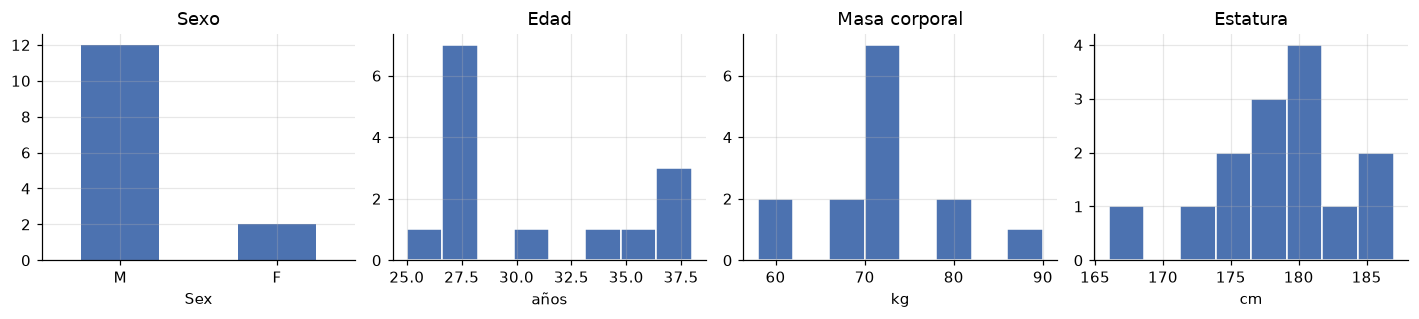

In [8]:
# Primer panel: sujetos por sexo; los demás: edad, masa corporal y estatura
fig, axes = plt.subplots(1, 4, figsize=(13, 3))
subj.Sex.value_counts().plot.bar(ax=axes[0], color="#4c72b0", rot=0, title="Sexo")
for ax, col, unit in zip(axes[1:], ["Age", "Body_mass", "Body_height"], ["años", "kg", "cm"]):
    ax.hist(subj[col], bins=8, color="#4c72b0", edgecolor="white")
    ax.set(title={"Age": "Edad", "Body_mass": "Masa corporal", "Body_height": "Estatura"}[col], xlabel=unit)
fig.tight_layout()

La cohorte es pequeña (14 sujetos, 12 hombres / 2 mujeres, de 25 a 38 años) y homogénea; por ello, **la generalización a sujetos nuevos no puede evaluarse mediante una partición aleatoria de ensayos**. La evaluación debe separar a los sujetos entre entrenamiento y prueba (por ejemplo, dejando un sujeto fuera en cada iteración). Las columnas antropométricas (`Shoulder_height`, `Arm_span`, ...) son entradas de calibración de Xsens y también podrían usarse como covariables.


# 4. Registros sEMG


Cada CSV de ensayo tiene una columna `Time` (tiempo Unix en ms) y 8 canales en tres versiones: `Raw_V_k` (voltaje crudo), `Norm_V_k` y `Norm_RMS_k` (señal rectificada y envolvente RMS, ambas en %MVC). Los registros MVC solo tienen `Time` + `Raw_V_k` (17 columnas en lugar de 25).

Interpretar 10 GB de CSV solo para obtener sus dimensiones es lento. Por eso se cuentan las filas y se leen la primera y la última marca de tiempo sin convertir todas las columnas. Aun así, se debe leer cada byte una vez: puede tomar unos segundos si los archivos están en la caché del sistema operativo o varios minutos si deben leerse desde disco. El resultado se guarda en caché.


In [9]:
def scan_csv(path):
    """Contar filas y leer las marcas de tiempo extremas sin convertir todo el CSV."""
    n = 0
    with open(path, "rb") as fh:
        fh.readline()                # Omitir la cabecera
        first = fh.readline()        # Primera fila de datos -> primera marca de tiempo
        fh.seek(0)
        # Contar saltos de línea en bloques de 16 MB, sin convertir las columnas del CSV
        while chunk := fh.read(1 << 24):
            n += chunk.count(b"\n")
        fh.seek(-4096, 2)    # Ir a los últimos 4 KB del archivo
        last = fh.read().strip().split(b"\n")[-1]    # Última línea -> última marca de tiempo
    # Restar 1 porque el conteo de líneas incluye la cabecera
    return n - 1, float(first.split(b",")[0]), float(last.split(b",")[0])

# Recorrer cada archivo para contar filas y leer las marcas de tiempo; guardar el resultado en caché
SCAN_CSV = CACHE_DIR / "emg_scan.csv"
t0 = time.time()
if SCAN_CSV.exists() and not REFRESH:
    scan = pd.read_csv(SCAN_CSV)
else:
    scan = pd.DataFrame([scan_csv(p) for p in emg.path], columns=["n_rows", "t0_ms", "t1_ms"])
    scan.insert(0, "file", emg.file.to_numpy())
    scan.to_csv(SCAN_CSV, index=False)

# Agregar n_rows, t0_ms y t1_ms al inventario
emg = emg.merge(scan, on="file")
emg["duration_s"] = (emg.t1_ms - emg.t0_ms) / 1000 # Duración de los registros en segundos
emg["fs_hz"] = (emg.n_rows - 1) / emg.duration_s   # Frecuencia efectiva: n_rows muestras corresponden a n_rows - 1 intervalos
print(f"Recorrido completado en {time.time() - t0:.0f} s, {emg.n_rows.sum() / 1e6:.1f} millones de muestras, {emg.duration_s.sum() / 3600:.1f} h registradas en total")
emg[["n_rows", "duration_s", "fs_hz"]].describe().round(1) # Número de filas, duración y frecuencia de cada CSV sEMG

# n_rows: total de registros del archivo
# duration_s: duración de la grabación
# fs_hz: frecuencia efectiva, (n_rows - 1) / duration_s

Recorrido completado en 0 s, 27.7 millones de muestras, 13.2 h registradas en total


,n_rows,duration_s,fs_hz
count,679.0,679.0,679.0
mean,40854.6,69.9,585.3
std,15403.0,16.7,156.6
min,9750.0,9.7,366.7
25%,32250.0,60.9,498.2
50%,37800.0,72.4,529.1
75%,45875.0,82.0,581.7
max,103950.0,113.9,1005.6


La frecuencia de muestreo **no es la misma en todos los archivos**: varía de ~370 a ~1006 Hz. Esto importa porque los índices de las etiquetas (sección 5) corresponden a muestras; convertirlos a segundos requiere la frecuencia de cada archivo. La siguiente gráfica muestra su relación con el sujeto.

Las diferencias de frecuencia (en Hz) presentan una variación importante entre sujetos.


subject,1,2,3,4,5,6,7,8,9,10,11,12,13,14
min,690.0,503.0,519.0,388.0,367.0,474.0,476.0,505.0,466.0,521.0,887.0,494.0,620.0,448.0
median,814.0,525.0,540.0,456.0,427.0,516.0,511.0,533.0,511.0,567.0,999.0,533.0,712.0,495.0
max,932.0,547.0,596.0,490.0,470.0,555.0,539.0,558.0,550.0,598.0,1006.0,586.0,891.0,542.0


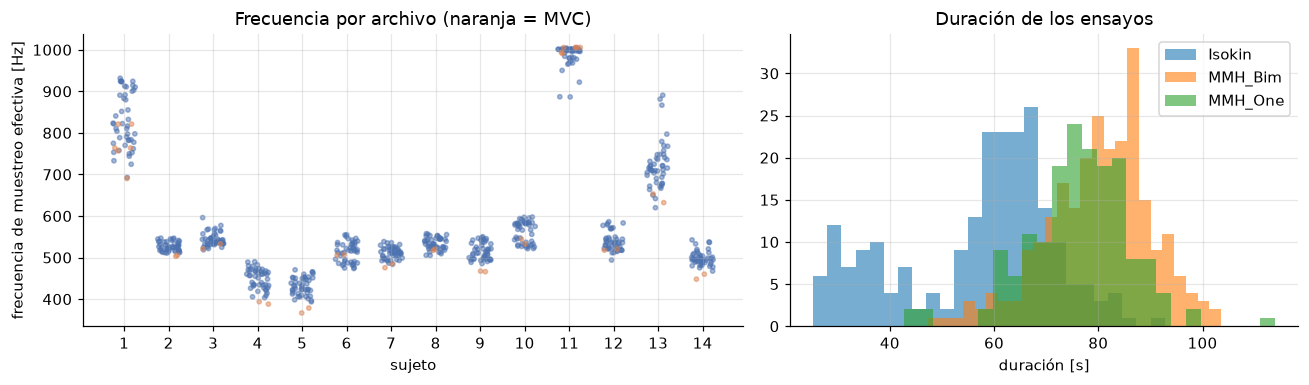

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.6), gridspec_kw={"width_ratios": [1.3, 1]})
# Izquierda: frecuencia por archivo y sujeto; dispersión horizontal con semilla fija para evitar superposición
rng = np.random.default_rng(0)
axes[0].scatter(emg.subject + rng.uniform(-0.25, 0.25, len(emg)), emg.fs_hz, s=8, alpha=0.5, c=np.where(emg.is_mvc, "#dd8452", "#4c72b0"))
axes[0].set(xlabel="sujeto", ylabel="frecuencia de muestreo efectiva [Hz]", title="Frecuencia por archivo (naranja = MVC)", xticks=range(1, 15))
# Derecha: histograma de duración de los ensayos por tarea
for task, g in emg[~emg.is_mvc].groupby("task"):
    axes[1].hist(g.duration_s, bins=25, alpha=0.6, label=task)
axes[1].set(xlabel="duración [s]", title="Duración de los ensayos"); axes[1].legend()
fig.tight_layout()

# Frecuencia mínima, mediana y máxima de cada sujeto
emg.groupby("subject").fs_hz.agg(["min", "median", "max"]).round(0).T

Dentro de cada archivo el muestreo es regular (comprobado para todos los archivos en la sección 6), pero la frecuencia cambia entre sujetos e incluso entre sesiones del mismo sujeto (por ejemplo, 690–932 Hz para el sujeto 1). El script `Process.m` de los autores también estima la frecuencia por archivo a partir del número de muestras y la duración; por tanto, no es una propiedad fija de la configuración de adquisición. Cualquier modelo que procese ventanas de muestras debe **remuestrear a una frecuencia común** o definir las ventanas por tiempo, en lugar de usar un número fijo de muestras.


# 5. Etiquetas de actividad


Cada ensayo tiene un archivo de etiquetas con una fila por segmento: `Start_Frame`, `End_Frame`, `Label`. Los índices se refieren a **filas del archivo sEMG** (el mayor `End_Frame` siempre es menor que el número de muestras sEMG). Las siete clases son:

| Código | Actividad | | Código | Actividad |
|---|---|---|---|---|
| `N` | Postura N (de pie, en posición neutra) | | `LT` | Levantar desde la mesa |
| `LF` | Levantar desde el suelo | | `W` | Caminar / transportar |
| `K` | Mantener el objeto levantado | | `PF` | Colocar en el suelo |
| `PT` | Colocar en la mesa | | | |

(Definiciones tomadas del artículo que utiliza este conjunto para reconocimiento de actividad: Sensors 25(21), 6705, 2025).


In [11]:
# Combinar los archivos de etiquetas en lab, con una fila por segmento etiquetado
# Calcular su duración y comprobar la consistencia de las etiquetas

trials = emg[~emg.is_mvc]    # Los archivos MVC solo tienen una ventana, sin etiquetas de actividad por clase
# Tabla de etiquetas de todos los archivos, identificando el archivo de cada segmento
lab = pd.concat([pd.read_csv(r.label_path).assign(file=r.file) for r in trials.itertuples()], ignore_index=True)
# Agregar metadatos del ensayo, número de muestras y frecuencia de la grabación
lab = lab.merge(trials[["file", "subject", "task", "side", "load_kg", "condition", "n_rows", "fs_hz"]], on="file")
lab["seg"] = lab.groupby("file").cumcount()    # Número de segmento dentro del archivo: 0, 1, 2, ...
lab["seg_samples"] = lab.End_Frame - lab.Start_Frame + 1    # Longitud en muestras; End_Frame es inclusivo
lab["seg_s"] = lab.seg_samples / lab.fs_hz    # Longitud en segundos
# Start_Frame siguiente menos End_Frame actual; negativo indica superposición y NaN el último segmento
lab["gap_to_next"] = lab.groupby("file").Start_Frame.shift(-1) - lab.End_Frame

display(lab.head(5))
# Comprobar clases válidas, etiquetas faltantes y segmentos fuera de la grabación
print(f"{len(lab)} segmentos en {lab.file.nunique()} archivos de etiquetas")
print("Valores de las etiquetas:", sorted(lab.Label.unique()), "| faltantes:", lab.Label.isna().sum())
print("Segmentos que terminan fuera del registro sEMG:", int((lab.End_Frame >= lab.n_rows).sum()))

,Start_Frame,End_Frame,Label,file,subject,task,side,load_kg,condition,n_rows,fs_hz,seg,seg_samples,seg_s,gap_to_next
0,14402,16884,N,Subj_01_Isokin_L_02kg_40bpm_EMG_data.csv,1,Isokin,L,2.0,40bpm,55050,692.828148,0,2483,3.583861,3.0
1,16887,17898,LT,Subj_01_Isokin_L_02kg_40bpm_EMG_data.csv,1,Isokin,L,2.0,40bpm,55050,692.828148,1,1012,1.460680,3.0
2,17901,19367,PT,Subj_01_Isokin_L_02kg_40bpm_EMG_data.csv,1,Isokin,L,2.0,40bpm,55050,692.828148,2,1467,2.117408,3.0
3,19370,23441,N,Subj_01_Isokin_L_02kg_40bpm_EMG_data.csv,1,Isokin,L,2.0,40bpm,55050,692.828148,3,4072,5.877359,2.0
4,23443,24431,LT,Subj_01_Isokin_L_02kg_40bpm_EMG_data.csv,1,Isokin,L,2.0,40bpm,55050,692.828148,4,989,1.427482,2.0


10612 segmentos en 643 archivos de etiquetas
Valores de las etiquetas: ['K', 'LF', 'LT', 'N', 'PF', 'PT', 'W'] | faltantes: 0
Segmentos que terminan fuera del registro sEMG: 0


Se esperan 46 registros sEMG por sujeto, distribuidos de la siguiente manera:

| Tarea | Por sujeto | Registros disponibles |
|---|---|---|
| Isokin | 16 | 223 |
| MMH_Bim | 18 | 252 |
| MMH_One | 12 | 168 |

El código lee los 643 archivos de etiquetas y apila sus filas en la tabla `lab`. Su tamaño final es la suma de las filas de todos los archivos:

* 643 archivos de etiquetas.
* 10,612 filas en total.
* Promedio de 16.5 segmentos por archivo, con un mínimo de 4 y un máximo de 19.


### Consistencia de las anotaciones

Los segmentos deben estar ordenados y no superponerse, con una separación pequeña (un par de muestras) entre segmentos consecutivos.


In [12]:
# Separación entre segmentos consecutivos; la moda indica el valor habitual
print("Separación entre segmentos consecutivos [muestras]:")
print(lab.gap_to_next.describe().round(1).to_string())
print("\nSeparación habitual (moda):", lab.gap_to_next.mode().iloc[0])

# Segmentos vacíos, invertidos o superpuestos con el siguiente
bad = lab[(lab.seg_samples <= 0) | (lab.gap_to_next < 0)]
print(f"\nSegmentos inconsistentes (vacíos, invertidos o superpuestos con el siguiente): {len(bad)} en {bad.file.nunique()} archivos")
# Mostrar todos los segmentos de cada archivo afectado
for f in bad.file.unique():
    print("\n", f)
    print(lab.loc[lab.file == f, ["seg", "Start_Frame", "End_Frame", "Label", "seg_samples"]].to_string(index=False))

Separación entre segmentos consecutivos [muestras]:
count    9969.0
mean        1.1
std        62.5
min     -4832.0
25%         2.0
50%         2.0
75%         3.0
max      1894.0

Separación habitual (moda): 2.0

Segmentos inconsistentes (vacíos, invertidos o superpuestos con el siguiente): 11 en 2 archivos

 Subj_02_MMH_One_R_02kg_Trial_2_EMG_data.csv
 seg  Start_Frame  End_Frame Label  seg_samples
   0         6941       7940     N         1000
   1         6941       9083    LF         2143
   2         7942      10445     K         2504
   3         9085      11608    PT         2524
   4        10447      12953     N         2507
   5        11610      13822    LT         2213
   6        12955      18656     W         5702
   7        13824      16764    PF         2941
   8        18658      17905     N         -752
   9        16766      19169    LF         2404
  10        17907      20198    PT         2292
  11        19171      21166     N         1996

 Subj_05_Isokin_L_0

Dos archivos tienen anotaciones inconsistentes y deben revisarse o excluirse antes del entrenamiento: en el ensayo unilateral del sujeto 2 se superponen dos secuencias de etiquetas (los tiempos de inicio y fin no son monótonos), y en el ensayo isocinético del sujeto 5 el último segmento `N` está vacío (`End_Frame < Start_Frame`).


In [13]:
BAD_LABEL_FILES = set(bad.file)    # Archivos con etiquetas inconsistentes, excluidos de los análisis que usan valid
valid = lab[~lab.file.isin(BAD_LABEL_FILES)]    # Tabla de etiquetas sin esos archivos

## Segmentos por clase y tarea
counts = lab.groupby(["task", "Label"]).size().unstack(fill_value=0)[LABEL_ORDER]
counts.loc["Total"] = counts.sum()    # Agregar la fila de totales
display(counts)

# Tabla de segmentos de cada archivo excluido
cols = ["seg", "Start_Frame", "End_Frame", "Label", "seg_samples", "gap_to_next"]
for f in sorted(BAD_LABEL_FILES):
    print(f)
    print(lab[lab["gap_to_next"] < 0].loc[lab.file == f, cols].to_string(index=False), "\n")

## Segmentos por clase y tarea
counts = lab.groupby(["task", "Label"]).size().unstack(fill_value=0)[LABEL_ORDER]
counts.loc["Total"] = counts.sum()    # Agregar la fila de totales
counts


Label,N,LF,K,PT,LT,W,PF
task,,,,,,,
Isokin,1107,0,56,884,884,0,0
MMH_Bim,1434,706,252,706,484,484,484
MMH_One,989,492,168,492,330,330,330
Total,3530,1198,476,2082,1698,814,814


Subj_02_MMH_One_R_02kg_Trial_2_EMG_data.csv
 seg  Start_Frame  End_Frame Label  seg_samples  gap_to_next
   0         6941       7940     N         1000       -999.0
   1         6941       9083    LF         2143      -1141.0
   2         7942      10445     K         2504      -1360.0
   3         9085      11608    PT         2524      -1161.0
   4        10447      12953     N         2507      -1343.0
   5        11610      13822    LT         2213       -867.0
   6        12955      18656     W         5702      -4832.0
   8        18658      17905     N         -752      -1139.0
   9        16766      19169    LF         2404      -1262.0
  10        17907      20198    PT         2292      -1027.0 

Subj_05_Isokin_L_04kg_80bpm_EMG_data.csv
Empty DataFrame
Columns: [seg, Start_Frame, End_Frame, Label, seg_samples, gap_to_next]
Index: [] 



Label,N,LF,K,PT,LT,W,PF
task,,,,,,,
Isokin,1107,0,56,884,884,0,0
MMH_Bim,1434,706,252,706,484,484,484
MMH_One,989,492,168,492,330,330,330
Total,3530,1198,476,2082,1698,814,814


Las clases presentes dependen de la tarea: **los ensayos isocinéticos solo contienen `N`, `LT`, `PT` y, en la condición estática, `K`**, mientras que las tareas MMH contienen las siete clases. `N` es, por mucho, la etiqueta más frecuente.

La siguiente figura muestra cómo se distribuye el *tiempo* registrado entre las clases (el desbalance que observaría un clasificador) y cuánto dura cada actividad.


Label,N,LF,K,PT,LT,W,PF
segments,3520.00,1196.00,475.00,2075.00,1692.00,813.00,813.00
hours,3.74,0.84,0.73,1.29,0.79,0.67,0.62
median_s,3.66,2.43,4.40,2.21,1.65,2.97,2.75
share_%,43.05,9.71,8.45,14.81,9.13,7.70,7.16


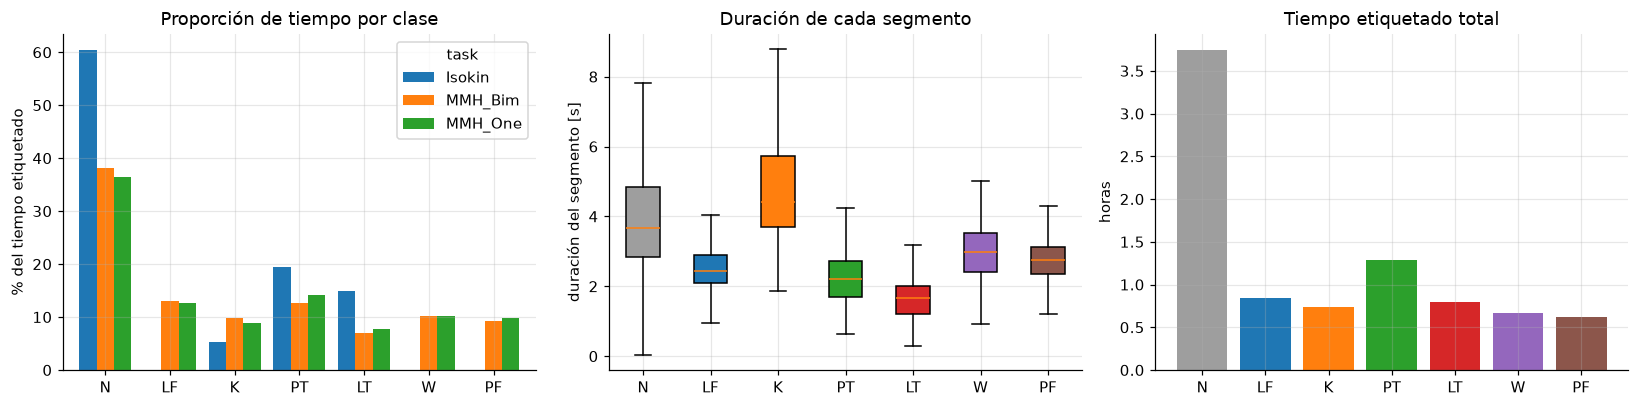

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))

# Izquierda: porcentaje de tiempo etiquetado por clase y tarea; cada tarea suma 100 %
time_share = valid.pivot_table(index="task", columns="Label", values="seg_s", aggfunc="sum", fill_value=0)[LABEL_ORDER]
(time_share.div(time_share.sum(axis=1), axis=0) * 100).T.plot.bar(ax=axes[0], rot=0, width=0.8)
axes[0].set(ylabel="% del tiempo etiquetado", title="Proporción de tiempo por clase", xlabel="")

# Centro: duración de los segmentos por clase, sin mostrar los valores atípicos
data = [valid.loc[valid.Label == l, "seg_s"] for l in LABEL_ORDER]
bp = axes[1].boxplot(data, tick_labels=LABEL_ORDER, patch_artist=True, showfliers=False)
# Colorear cada caja según su clase
for patch, l in zip(bp["boxes"], LABEL_ORDER):
    patch.set_facecolor(LABEL_COLORS[l])
axes[1].set(ylabel="duración del segmento [s]", title="Duración de cada segmento")

# Derecha: horas etiquetadas totales por clase
axes[2].bar(LABEL_ORDER, valid.groupby("Label").seg_s.sum().reindex(LABEL_ORDER) / 3600, color=[LABEL_COLORS[l] for l in LABEL_ORDER])
axes[2].set(ylabel="horas", title="Tiempo etiquetado total")
fig.tight_layout()

# Resumen por clase: segmentos, horas, duración mediana y porcentaje de tiempo etiquetado
tot = valid.groupby("Label").agg(segments=("seg", "size"), hours=("seg_s", lambda s: s.sum() / 3600), median_s=("seg_s", "median"))
tot["share_%"] = tot.hours / tot.hours.sum() * 100
tot.reindex(LABEL_ORDER).round(2).T

### Estructura de un ensayo

Las secuencias de etiquetas siguen un protocolo. La siguiente tabla muestra las secuencias completas más frecuentes.


In [15]:
# Secuencia de etiquetas del ensayo como texto, por ejemplo "N LF K PT N ..."
seqs = valid.groupby(["task", "file"]).Label.apply(" ".join).reset_index()
# Contar los ensayos de cada secuencia y conservar las 3 más frecuentes por tarea
top = seqs.groupby(["task", "Label"]).size().rename("trials").reset_index().sort_values(["task", "trials"], ascending=[True, False])
top.groupby("task").head(3).reset_index(drop=True)

,task,Label,trials
0,Isokin,N LT PT N LT PT N LT PT N LT PT N LT PT N,140
1,Isokin,N LT K PT N,56
2,Isokin,N LT PT N LT PT N LT PT N LT PT N LT PT N LT PT N,15
3,MMH_Bim,N LF K PT N LT W PF N LF PT N LT W PF N LF PT N,210
4,MMH_Bim,N LF K PT N LT W PF N,16
5,MMH_Bim,N LF K PT N LT W PF N LF PT N LT W PF N,14
6,MMH_One,N LF K PT N LT W PF N LF PT N LT W PF N LF PT N,158
7,MMH_One,N LF K PT N LT W PF N,3
8,MMH_One,N LF K PT N LT W PF N LF PT N LT W PF N,3


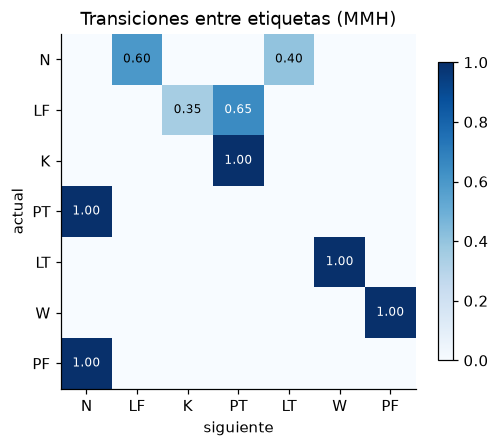

In [16]:
## Probabilidades P(etiqueta siguiente | etiqueta actual), solo para ensayos MMH
mmh = valid[valid.task.str.startswith("MMH")].copy()
# Etiqueta del siguiente segmento del mismo archivo; NaN para el último
mmh["next"] = mmh.groupby("file").Label.shift(-1)
# Contar los pares de clases conservando las 7 x 7 combinaciones, incluso las que no ocurren
# Dividir cada fila por su total para obtener P(siguiente | actual)
trans = pd.crosstab(mmh.Label, mmh["next"]).reindex(index=LABEL_ORDER, columns=LABEL_ORDER, fill_value=0)
trans = trans.div(trans.sum(axis=1), axis=0)

fig, ax = plt.subplots(figsize=(5.2, 4.4))
im = ax.imshow(trans, cmap="Blues", vmin=0, vmax=1)
ax.set(xticks=range(7), yticks=range(7), xticklabels=LABEL_ORDER, yticklabels=LABEL_ORDER, xlabel="siguiente", ylabel="actual", title="Transiciones entre etiquetas (MMH)")
ax.grid(False)
# Escribir cada probabilidad no nula; usar texto blanco sobre celdas oscuras
for i, j in product(range(7), range(7)):
    if trans.iloc[i, j] > 0:
        ax.text(j, i, f"{trans.iloc[i, j]:.2f}", ha="center", va="center", color="white" if trans.iloc[i, j] > 0.6 else "black", fontsize=8)
fig.colorbar(im, shrink=0.8);

Los ensayos MMH siguen una secuencia fija: `N → LF → (K) → PT → N → LT → W → PF → N → LF → PT → N → LT → W → PF → N → LF → PT → N`; es decir, tres levantamientos desde el suelo y dos desde la mesa, con `K` solo en el primer levantamiento. El orden es tan regular que un modelo secuencial puede aprovechar el contexto, mientras que un clasificador que recibe una sola ventana de 1 s debe separar movimientos parecidos que ocurren a distintas alturas (`LF` frente a `LT`, `PT` frente a `PF`).

### Cobertura de etiquetas de cada grabación


,labeled_frac,lead_s,tail_s
count,641.00,641.00,641.00
mean,0.67,16.84,5.45
std,0.13,5.86,5.00
min,0.27,0.00,0.06
25%,0.62,13.75,2.67
50%,0.69,16.59,4.66
75%,0.75,20.26,6.83
max,0.99,38.75,50.15


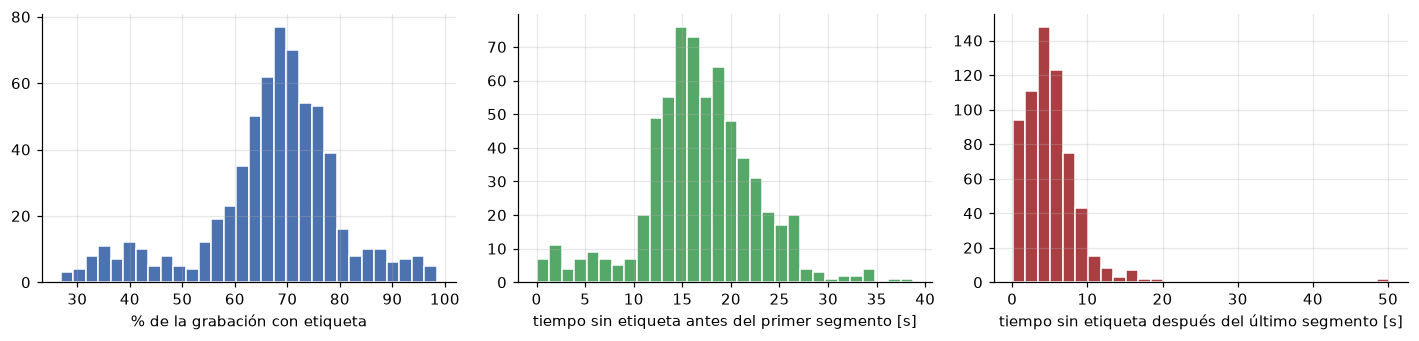

In [17]:
# Cobertura por archivo: muestras inicial/final etiquetadas, total etiquetado y tamaño de grabación
cov = valid.groupby("file").agg(first=("Start_Frame", "min"), last=("End_Frame", "max"), labeled=("seg_samples", "sum"), n_rows=("n_rows", "first"), fs=("fs_hz", "first"))
cov["labeled_frac"] = cov.labeled / cov.n_rows    # Fracción etiquetada de la grabación
cov["lead_s"] = cov["first"] / cov.fs    # Segundos sin etiqueta al inicio
cov["tail_s"] = (cov.n_rows - cov["last"]) / cov.fs    # Segundos sin etiqueta al final

# Histogramas de cobertura y de tiempo sin etiqueta antes y después de los segmentos
fig, axes = plt.subplots(1, 3, figsize=(13, 3.2))
axes[0].hist(cov.labeled_frac * 100, bins=30, color="#4c72b0", edgecolor="white"); axes[0].set(xlabel="% de la grabación con etiqueta")
axes[1].hist(cov.lead_s, bins=30, color="#55a868", edgecolor="white"); axes[1].set(xlabel="tiempo sin etiqueta antes del primer segmento [s]")
axes[2].hist(cov.tail_s, bins=30, color="#AA3F43", edgecolor="white"); axes[2].set(xlabel="tiempo sin etiqueta después del último segmento [s]")
fig.tight_layout()
cov[["labeled_frac", "lead_s", "tail_s"]].describe().round(2)

En promedio, solo ~dos tercios de cada grabación tienen etiquetas: la sEMG comienza una mediana de ~17 s antes del primer segmento y continúa ~5 s después del último. Esas muestras **no tienen etiqueta** y deben descartarse al construir ventanas, o asignarse a `N` si existe una justificación.

### Ventanas MVC

Cada `*_EMG_range.csv` señala la ventana del registro MVC usada para calcular la amplitud de referencia (`Process.m` promedia la envolvente RMS dentro de ella).


In [18]:
mvc = emg[emg.is_mvc].copy()    # Registros MVC
# Cada *_range.csv tiene una fila con Start_Frame y End_Frame para la ventana de referencia MVC
rng_df = pd.concat([pd.read_csv(p) for p in mvc.label_path], ignore_index=True)
# Duración en segundos; .to_numpy() alinea por posición con las filas de mvc
mvc["win_s"] = (rng_df.End_Frame - rng_df.Start_Frame + 1).to_numpy() / mvc.fs_hz.to_numpy()
print(mvc.win_s.describe().round(2).to_string())

count    36.00
mean      3.46
std       1.01
min       1.99
25%       2.44
50%       3.84
75%       4.10
max       5.46


# 6. Calidad de la señal sEMG

Un único recorrido de todos los CSV calcula, por archivo: regularidad de las marcas de tiempo, valores faltantes, estadísticas de amplitud de los 8 canales crudos y, para los ensayos, percentiles de la señal normalizada. También calcula, por segmento etiquetado, la media `Norm_RMS` de cada canal (usada en la sección 8). El resultado se guarda en caché.


In [19]:
# Estadísticas de calidad por archivo; cada CSV se lee una vez y los resultados se guardan en caché
# FILE_CSV: una fila por archivo; SEG_CSV: media Norm_RMS de cada segmento etiquetado
FILE_CSV, SEG_CSV = CACHE_DIR / "emg_file_stats.csv", CACHE_DIR / "emg_segment_stats.csv"
CH = range(1, N_CH + 1)    # Números de canal del 1 al 8


def scan_emg(row):
    # MVC tiene columnas crudas y rectificadas, sin normalizadas; aquí solo se leen las crudas
    cols = ["Time"] + RAW + ([] if row.is_mvc else NORM_V + NORM_RMS)
    d = pd.read_csv(row.path, usecols=cols, dtype=np.float64)
    t = d["Time"].to_numpy()
    dt = np.diff(t)    # Periodo de muestreo entre muestras consecutivas [ms]
    raw = d[RAW].to_numpy()    # Dimensiones: número de muestras x 8 canales
    # Revisar valores faltantes, periodo de muestreo y saltos mayores a 1.5 veces la mediana
    # También detectar marcas de tiempo que no aumentan
    stats = dict(
        file=row.file, n_nan=int(d.isna().to_numpy().sum()),
        dt_med_ms=np.median(dt), dt_min_ms=dt.min(), dt_max_ms=dt.max(),
        n_gaps=int((dt > 1.5 * np.median(dt)).sum()), n_nonmono=int((dt <= 0).sum()),
    )
    # Por canal: media, desviación estándar y mayor valor absoluto de la señal cruda [V]
    for c, m, s, a in zip(CH, raw.mean(0), raw.std(0), np.abs(raw).max(0)):
        stats.update({f"raw_mean_{c}": m, f"raw_std_{c}": s, f"raw_absmax_{c}": a})
    segs = []
    if not row.is_mvc:
        # Por canal: percentil 99 de Norm_RMS y máximo de Norm_V para revisar la escala %MVC
        rms, nv = d[NORM_RMS].to_numpy(), d[NORM_V].to_numpy()
        for c, p99, mx in zip(CH, np.percentile(rms, 99, axis=0), nv.max(0)):
            stats.update({f"rms_p99_{c}": p99, f"normv_max_{c}": mx})
        # Media Norm_RMS por canal y segmento etiquetado, usada en la sección 8
        lab_df = pd.read_csv(row.label_path)
        for s0, s1, name in lab_df.itertuples(index=False):
            # Omitir segmentos invertidos o que terminan fuera de la grabación
            if s1 < s0 or s1 >= len(d):
                continue
            # End_Frame es inclusivo; por eso se usa s1 + 1
            segs.append(dict(file=row.file, Start_Frame=s0, End_Frame=s1, Label=name,
                             **{f"rms_{c}": v for c, v in zip(CH, rms[s0:s1 + 1].mean(0))}))
    return stats, segs


# Reutilizar la caché o recorrer todos los archivos, mostrando avance cada 100
if FILE_CSV.exists() and SEG_CSV.exists() and not REFRESH:
    file_stats, seg_stats = pd.read_csv(FILE_CSV), pd.read_csv(SEG_CSV)
else:
    t0, fs_rows, sg_rows = time.time(), [], []
    for i, row in enumerate(emg.itertuples(), 1):
        st, sg = scan_emg(row)
        fs_rows.append(st); sg_rows += sg
        if i % 100 == 0:
            print(f"{i}/{len(emg)} archivos, {time.time() - t0:.0f} s")
    file_stats, seg_stats = pd.DataFrame(fs_rows), pd.DataFrame(sg_rows)
    file_stats.to_csv(FILE_CSV, index=False); seg_stats.to_csv(SEG_CSV, index=False)
    print(f"Terminado en {time.time() - t0:.0f} s")

# Agregar metadatos de sujeto, tarea, lado y carga a las estadísticas
file_stats = emg[["file", "subject", "task", "side", "load_kg", "condition", "is_mvc", "fs_hz"]].merge(file_stats, on="file")
print(file_stats.shape, seg_stats.shape)

(679, 54) (10610, 12)


### Valores faltantes y marcas de tiempo


In [20]:
# Revisar marcas de tiempo: faltantes, orden, saltos y variación del periodo
print("Valores faltantes (todos los archivos y columnas leídas):", int(file_stats.n_nan.sum()))
print("Marcas de tiempo no monótonas:", int(file_stats.n_nonmono.sum()))
print("Intervalos mayores a 1.5 veces el periodo de muestreo:", int(file_stats.n_gaps.sum()))
# Variación relativa del periodo dentro de cada archivo
jit = (file_stats.dt_max_ms - file_stats.dt_min_ms) / file_stats.dt_med_ms
print(f"Máxima variación del periodo por archivo (máximo-mínimo)/mediana: {jit.max():.3%}")

Valores faltantes (todos los archivos y columnas leídas): 0
Marcas de tiempo no monótonas: 0
Intervalos mayores a 1.5 veces el periodo de muestreo: 0
Máxima variación del periodo por archivo (máximo-mínimo)/mediana: 1.011%


No hay valores faltantes y las marcas de tiempo son estrictamente crecientes, con un periodo constante dentro de cada archivo (la variación de ≤ 1 % corresponde al redondeo de las marcas a 0.01 ms). Por tanto, una sola frecuencia de muestreo por archivo basta para describir el eje temporal.

### Amplitud y valores atípicos

En un archivo típico, los canales crudos tienen una desviación estándar de unas décimas a unos pocos mV y un pico |señal cruda| de ~15 mV (mediana); el 90 % de los archivos está por debajo de ~34 mV. La tabla muestra los archivos con el mayor pico absoluto entre sus canales.


In [21]:
# Columnas por canal de scan_emg: pico absoluto y desviación estándar de la señal cruda
AMAX, ASTD = [f"raw_absmax_{c}" for c in CH], [f"raw_std_{c}" for c in CH]
# Amplitud por archivo en mV: mayor pico de cualquier canal y desviación estándar mediana
# También calcular la desviación estándar del canal más ruidoso
file_stats["absmax_mV"] = file_stats[AMAX].max(axis=1) * 1e3
file_stats["std_med_mV"] = file_stats[ASTD].median(axis=1) * 1e3
file_stats["std_max_mV"] = file_stats[ASTD].max(axis=1) * 1e3

print(file_stats.absmax_mV.describe(percentiles=[.5, .9, .99]).round(1).to_string())
# Los 8 archivos con los picos más altos
file_stats.sort_values("absmax_mV", ascending=False)[["file", "absmax_mV", "std_med_mV", "std_max_mV"]].head(8).round(1)

count     679.0
mean       26.9
std       119.3
min         3.6
50%        15.1
90%        34.0
99%       104.1
max      1951.7


,file,absmax_mV,std_med_mV,std_max_mV
322,Subj_07_MMH_Bim_R_08kg_Trial_3_EMG_data.csv,1951.7,2.5,739.8
324,Subj_07_MMH_Bim_R_12kg_Trial_2_EMG_data.csv,1849.5,4.4,194.3
323,Subj_07_MMH_Bim_R_12kg_Trial_1_EMG_data.csv,1581.7,2.7,487.7
300,Subj_07_Isokin_R_02kg_40bpm_EMG_data.csv,150.7,7.8,19.8
303,Subj_07_Isokin_R_02kg_St_EMG_data.csv,122.2,5.7,23.3
294,Subj_07_Isokin_L_02kg_80bpm_EMG_data.csv,115.1,2.2,8.0
301,Subj_07_Isokin_R_02kg_60bpm_EMG_data.csv,113.0,4.1,13.1
293,Subj_07_Isokin_L_02kg_60bpm_EMG_data.csv,101.6,2.2,8.3


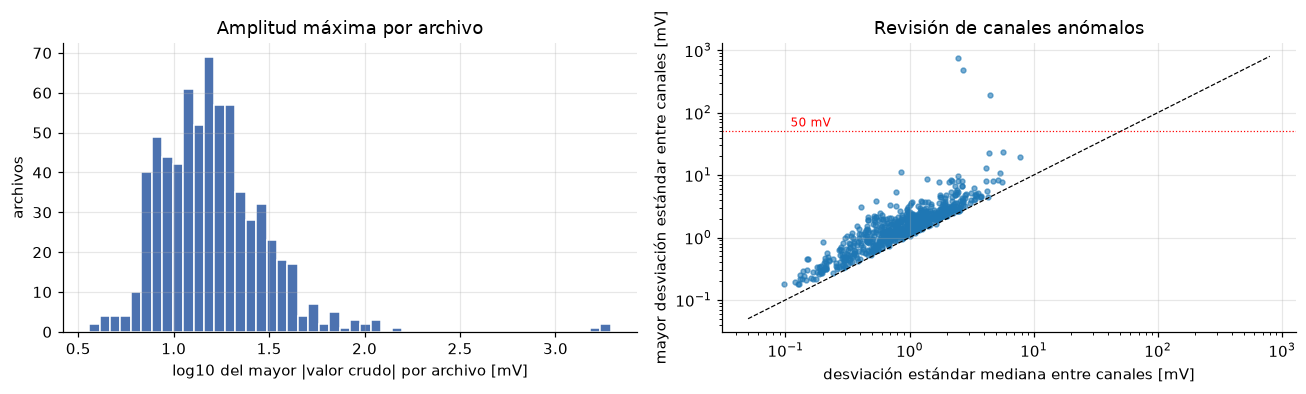

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
# Izquierda: amplitud máxima por archivo en escala logarítmica
axes[0].hist(np.log10(file_stats.absmax_mV), bins=50, color="#4c72b0", edgecolor="white")
axes[0].set(xlabel="log10 del mayor |valor crudo| por archivo [mV]", ylabel="archivos", title="Amplitud máxima por archivo")
# Derecha: canal más ruidoso frente al típico; lejos de la diagonal indica un canal anómalo
axes[1].scatter(file_stats.std_med_mV, file_stats.std_max_mV, s=10, alpha=0.6)
axes[1].set(xscale="log", yscale="log", xlabel="desviación estándar mediana entre canales [mV]", ylabel="mayor desviación estándar entre canales [mV]", title="Revisión de canales anómalos")
axes[1].plot([0.05, 800], [0.05, 800], "k--", lw=0.8)    # Diagonal: todos los canales tienen una variación similar
# Umbral de valores atípicos de 50 mV, aplicado en la siguiente celda
axes[1].axhline(50, color="r", lw=0.8, ls=":"); axes[1].text(0.11, 60, "50 mV", color="r", fontsize=8)
fig.tight_layout()

Se observa una separación clara: tres archivos tienen al menos un canal con desviación estándar superior a 100 mV, mientras que en los demás ningún canal supera ~25 mV. La siguiente regla marca un archivo cuando algún canal tiene una desviación estándar superior a 50 mV.


In [23]:
## Regla: marcar archivos con algún canal de desviación estándar > 50 mV; lo típico es ~1 mV
STD_LIMIT_MV = 50
outliers = file_stats[file_stats.std_max_mV > STD_LIMIT_MV]    # Al menos un canal supera el límite
BAD_EMG_FILES = set(outliers.file)    # Excluir de los análisis de señal siguientes
print(f"{len(outliers)} archivo(s) con algún canal de desviación estándar > {STD_LIMIT_MV} mV:")
# Mostrar la desviación estándar de cada canal para localizar las anomalías
for r in outliers.itertuples():
    stds = " ".join(f"{getattr(r, f'raw_std_{c}') * 1e3:7.1f}" for c in CH)
    print(f"  {r.file}\n    desviación estándar por canal [mV]: {stds}")

## Los demás archivos con |señal cruda| > 100 mV son ruidosos, sin fallas continuas; desviación <= 25 mV
noisy = file_stats[(file_stats.absmax_mV > 100) & ~file_stats.file.isin(BAD_EMG_FILES)]
print(f"\n{len(noisy)} archivos ruidosos (|señal cruda| > 100 mV, conservados): sujeto(s) {sorted(int(s) for s in noisy.subject.unique())}")

3 archivo(s) con algún canal de desviación estándar > 50 mV:
  Subj_07_MMH_Bim_R_08kg_Trial_3_EMG_data.csv
    desviación estándar por canal [mV]:     0.9     1.4     1.1     1.4     3.5     4.0   363.3   739.8
  Subj_07_MMH_Bim_R_12kg_Trial_1_EMG_data.csv
    desviación estándar por canal [mV]:     1.3     0.9     0.6     1.1     4.1     6.0   487.7   252.0
  Subj_07_MMH_Bim_R_12kg_Trial_2_EMG_data.csv
    desviación estándar por canal [mV]:     3.7     6.3     3.1     5.1     2.9     1.9   194.3   125.5

5 archivos ruidosos (|señal cruda| > 100 mV, conservados): sujeto(s) [7]


Los tres archivos marcados (todos del sujeto 7, brazo derecho) presentan amplitudes de cientos de mV hasta ~2 V en los canales 7 y 8, entre 2 y 3 órdenes de magnitud por encima del resto. Esto indica un artefacto por electrodo/cable suelto o saturación, en lugar de actividad muscular. También produce valores normalizados desproporcionados (`Norm_V` de hasta ~3·10⁵ %MVC en el primero), por lo que estos archivos deben excluirse o sus canales deben enmascararse; aquí se excluyen del resto del análisis. Otros cinco archivos del mismo sujeto tienen picos superiores a 100 mV, pero una desviación estándar normal: se conservan como registros ruidosos. El sujeto 7 representa la sesión con mayor ruido.

*Otros cinco archivos son ruidosos, pero válidos:*

Son cinco ensayos Isokin del mismo sujeto (L_02kg_60bpm, L_02kg_80bpm, R_02kg_40bpm, R_02kg_60bpm, R_02kg_St). Presentan picos entre 100 y 150 mV; sin embargo, su desviación estándar máxima varía entre 8 y 23 mV, lo que indica que la señal permanece en un intervalo razonable durante la mayor parte del tiempo. Los picos parecen artefactos aislados, en lugar de una falla continua del electrodo. Por este motivo se conservan, aunque la sesión del sujeto 7 requiere mayor atención.

### **Amplitud por sujeto y canal**

Mediana de la desviación estándar de la señal cruda en los ensayos de cada sujeto, excluyendo los archivos marcados:


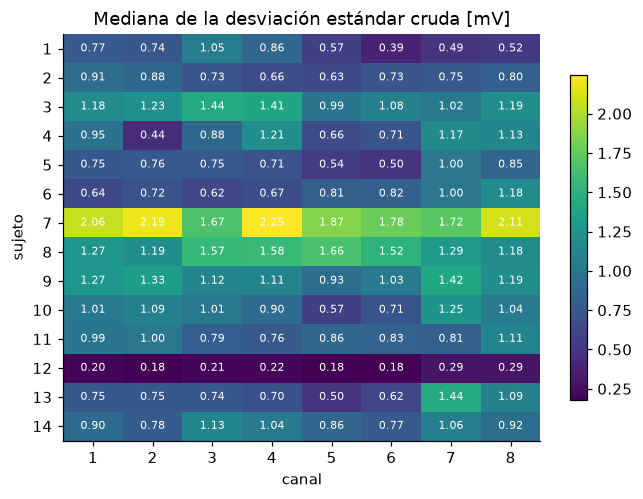

In [24]:
good = file_stats[~file_stats.file.isin(BAD_EMG_FILES)]    # Archivos sin las fallas detectadas
amp = good.groupby("subject")[ASTD].median() * 1e3    # Mediana de la desviación estándar cruda [mV] por sujeto y canal
amp.columns = list(CH)    # Números de canal del 1 al 8

# Mapa de calor de sujetos x canales, con el valor escrito en cada celda
fig, ax = plt.subplots(figsize=(7, 4.8))
im = ax.imshow(amp, cmap="viridis", aspect="auto")
ax.set(xticks=range(N_CH), xticklabels=list(CH), yticks=range(14), yticklabels=amp.index, xlabel="canal", ylabel="sujeto", title="Mediana de la desviación estándar cruda [mV]")
ax.grid(False)
for i, j in product(range(14), range(N_CH)):
    ax.text(j, i, f"{amp.iloc[i, j]:.2f}", ha="center", va="center", color="white", fontsize=7)
fig.colorbar(im, shrink=0.8);

La amplitud cruda difiere aproximadamente un orden de magnitud **entre sujetos** (~0.2 mV para el sujeto 12 frente a ~2 mV para el sujeto 7) y es relativamente similar entre canales de un mismo sujeto. Es un efecto del sujeto y de la configuración (impedancia de la piel, ganancia y colocación de electrodos), parcialmente aumentado por la deriva lenta de la línea base de la señal cruda (sección 7), que también contribuye a la desviación estándar. Por ello, los autores normalizan con la MVC de cada sujeto: el voltaje crudo no debería usarse como entrada de un modelo sin normalización por sujeto.

### Señal normalizada (%MVC)

`Norm_RMS` es la envolvente RMS expresada como porcentaje de la MVC del mismo sujeto. Un valor superior al 100 % indica que la tarea produjo más actividad que la contracción «máxima» de referencia, lo que puede reflejar una MVC subestimada (su ventana dura solo 2–5 s; véase la sección 5).


In [25]:
# Solo ensayos: MVC no tiene Norm_RMS; un p99 por archivo y canal
p99 = good[~good.is_mvc][[f"rms_p99_{c}" for c in CH]]
print("Percentil 99 de Norm_RMS por archivo y canal [%MVC]:")
print(p99.stack().describe(percentiles=[.5, .9]).round(1).to_string())
print(f"\nArchivos con algún canal por encima de 100 %MVC en p99: {(p99.max(axis=1) > 100).sum()} / {len(p99)}")
nv = good[~good.is_mvc][[f"normv_max_{c}" for c in CH]].stack()
print(f"Máximo de Norm_V: mediana {nv.median():.0f} %, p99 {nv.quantile(.99):.0f} %, máximo {nv.max():.0f} % (rectificada, sin suavizar -> con picos pronunciados)")

Percentil 99 de Norm_RMS por archivo y canal [%MVC]:
count    5120.0
mean       95.2
std        74.7
min         6.1
50%        78.6
90%       170.2
max      1581.8

Archivos con algún canal por encima de 100 %MVC en p99: 434 / 640
Máximo de Norm_V: mediana 394 %, p99 4208 %, máximo 13498 % (rectificada, sin suavizar -> con picos pronunciados)


Superar el 100 %MVC es frecuente en la mayoría de los archivos. Por tanto, `Norm_RMS` **no está acotada entre 0 y 100** y los valores %MVC deben interpretarse como una escala por sujeto, no como un esfuerzo absoluto. `Norm_V` (rectificada y sin suavizar) alcanza miles de %MVC y presenta picos mucho más pronunciados que la envolvente RMS.


# 7. Ensayos de ejemplo

Señal sEMG cruda del canal 1 y envolvente `Norm_RMS` de los 8 canales, con los segmentos anotados sombreados.


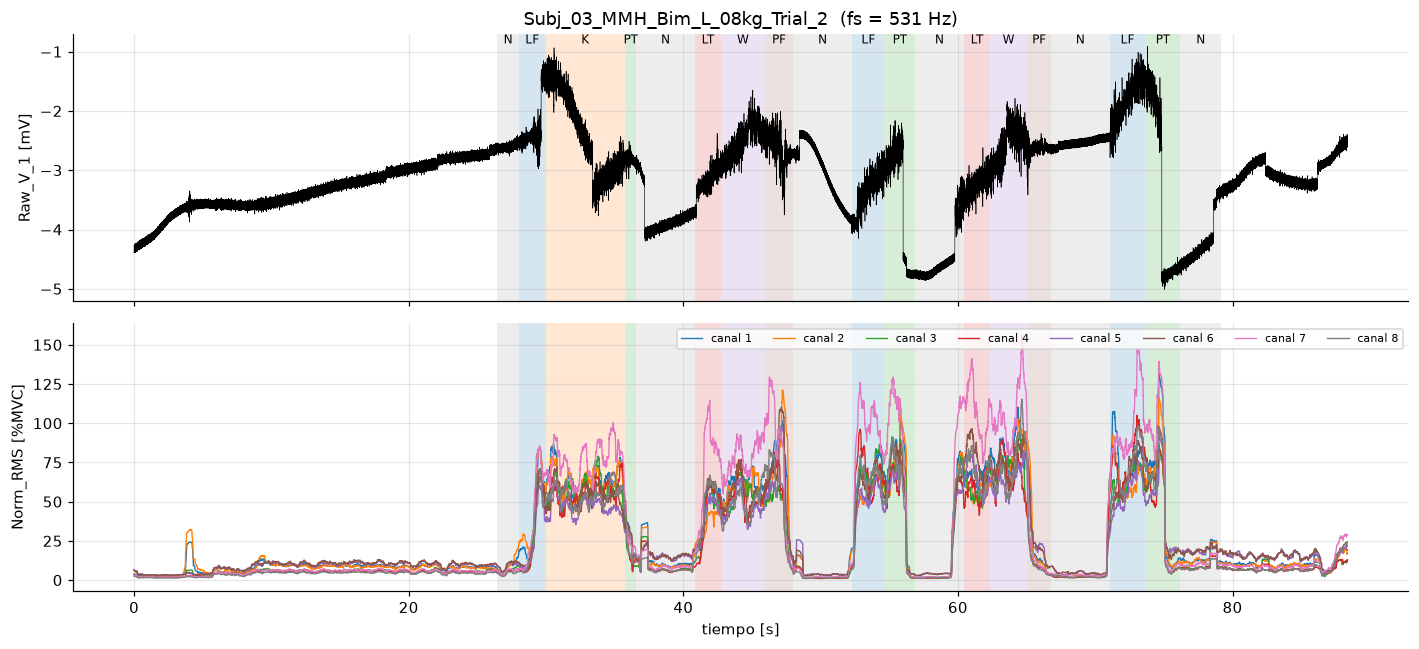

In [26]:
emg_by_key = emg.set_index("key")    # Buscar los archivos por nombre de ensayo


def plot_trial(key):
    # Ensayo: canal crudo 1 arriba y envolventes Norm_RMS abajo, con segmentos etiquetados sombreados
    r = emg_by_key.loc[key]
    d, labs = pd.read_csv(r.path), pd.read_csv(r.label_path)
    t = (d.Time.to_numpy() - d.Time.iloc[0]) / 1000    # Tiempo desde el inicio de la grabación [s]
    fig, axes = plt.subplots(2, 1, figsize=(13, 6), sharex=True)
    # Arriba: señal cruda del canal 1 en mV
    axes[0].plot(t, d.Raw_V_1 * 1e3, lw=0.4, color="k")
    axes[0].set(ylabel="Raw_V_1 [mV]", title=f"{key}  (fs = {r.fs_hz:.0f} Hz)")
    # Abajo: una línea por canal
    for c in NORM_RMS:
        axes[1].plot(t, d[c], lw=0.9, label=c.replace("Norm_RMS_", "canal "))
    axes[1].set(ylabel="Norm_RMS [%MVC]", xlabel="tiempo [s]")
    axes[1].legend(ncol=8, fontsize=7, loc="upper right")
    # Sombrear cada segmento; Start/End_Frame son índices de muestra y t[frame] proporciona su tiempo
    for s0, s1, name in labs.itertuples(index=False):
        if s1 < s0:    # Omitir segmentos invertidos
            continue
        # min(...) mantiene el índice dentro de la grabación si la etiqueta termina fuera
        for ax in axes:
            ax.axvspan(t[s0], t[min(s1, len(t) - 1)], color=LABEL_COLORS[name], alpha=0.18, lw=0)
        # Nombre de la clase en la parte superior del segmento
        axes[0].text((t[s0] + t[min(s1, len(t) - 1)]) / 2, axes[0].get_ylim()[1], name, ha="center", va="top", fontsize=8)
    fig.tight_layout()
    return d    # Devolver los datos para reutilizarlos en la gráfica de correlación


d_bim = plot_trial("Subj_03_MMH_Bim_L_08kg_Trial_2")    # Ejemplo bimanual: sujeto 3, lado izquierdo, 8 kg

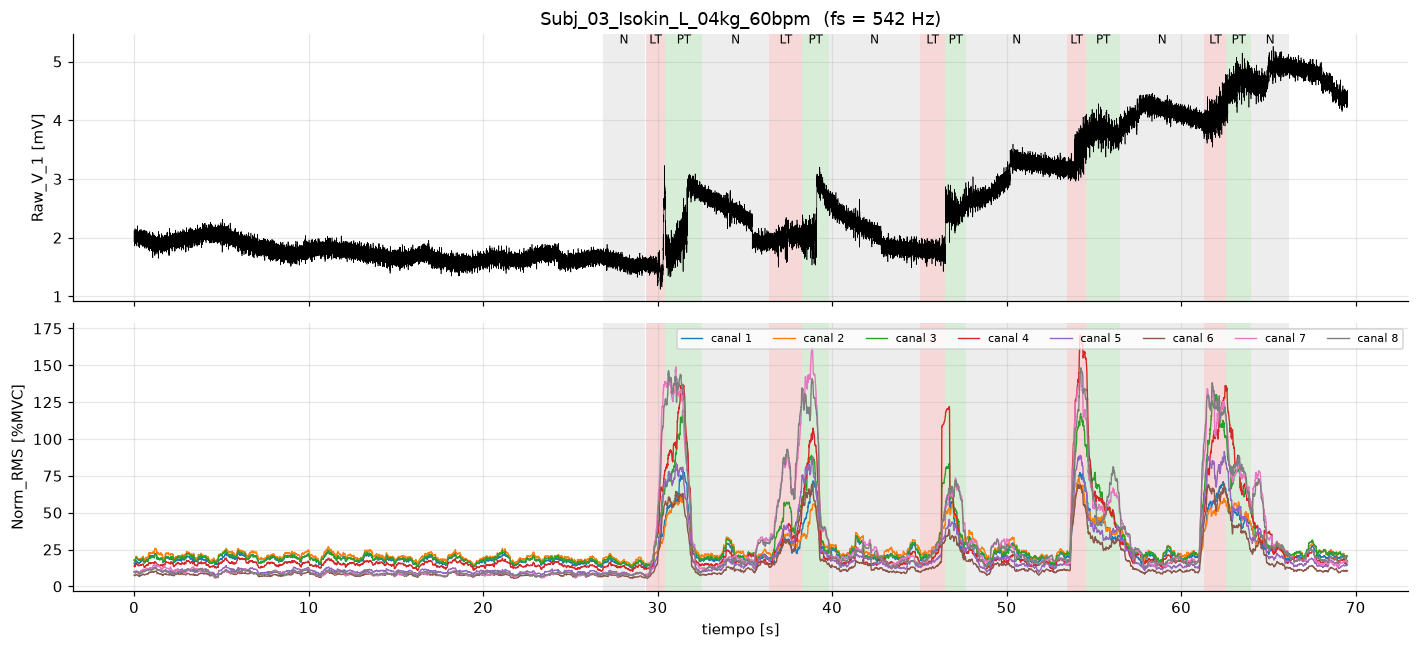

In [27]:
d_iso = plot_trial("Subj_03_Isokin_L_04kg_60bpm")    # Ejemplo isocinético: sujeto 3, lado izquierdo, 4 kg, 60 bpm

En el ensayo bimanual, la envolvente pasa de ~5–10 %MVC en reposo a 50–100 % cuando se levanta el objeto (`LF`, `LT`), permanece elevada mientras se sostiene o transporta y disminuye durante `N`. Los primeros ~26 s de la grabación no tienen etiquetas. En el ensayo isocinético, cada repetición (`LT` + `PT`) aparece como una ráfaga.

La señal cruda (arriba) muestra el otro problema mencionado: un desplazamiento de la línea base de varios mV y una deriva lenta, sobre los que la actividad muscular aparece como un cambio en el ancho del trazo. El filtro pasa altas de `Process.m` elimina este componente antes de calcular la envolvente.

Correlación entre canales en el mismo ensayo bimanual:


Señal cruda: correlación mínima fuera de la diagonal = 0.67


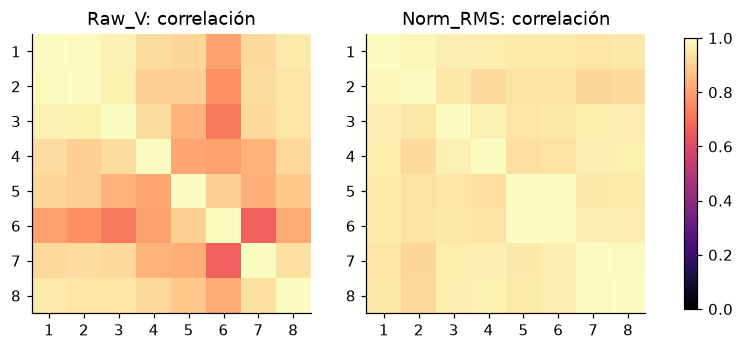

In [28]:
# Correlación entre los 8 canales: señal cruda a la izquierda y Norm_RMS a la derecha
fig, axes = plt.subplots(1, 2, figsize=(9, 4))
for ax, cols, title in zip(axes, (RAW, NORM_RMS), ("Raw_V", "Norm_RMS")):
    c = d_bim[cols].corr().to_numpy()
    im = ax.imshow(c, vmin=0, vmax=1, cmap="magma"); ax.grid(False)
    ax.set(title=f"{title}: correlación", xticks=range(8), yticks=range(8), xticklabels=range(1, 9), yticklabels=range(1, 9))
fig.colorbar(im, ax=axes, shrink=0.8)
# Menor correlación entre canales distintos; excluir la diagonal
print(f"Señal cruda: correlación mínima fuera de la diagonal = {np.min(d_bim[RAW].corr().to_numpy()[~np.eye(8, dtype=bool)]):.2f}")

Los canales crudos están **fuertemente correlacionados entre sí** (correlación fuera de la diagonal ≥ 0.67 en este ejemplo), por lo que no se comportan como señales musculares independientes: la deriva lenta compartida domina la correlación. El procesamiento de los autores (`Process.m`) aplica un filtro de rechazo a 50 Hz y un filtro Butterworth pasa banda (frecuencia de corte inferior de 20 Hz) antes de rectificar y calcular la envolvente. Usar `Norm_RMS` ofrece una base más segura que `Raw_V`.

La correspondencia entre los canales 1–8 y los músculos **no está documentada** en los archivos. La descripción de Zenodo enumera cuatro músculos del brazo (tríceps, extensor de los dedos, bíceps y braquiorradial), pero cada archivo tiene 8 canales y no indica qué músculo corresponde a cada uno. Esto debe confirmarse con el artículo antes de interpretar los canales individualmente.


# 8. sEMG y actividad

Para explorar si la sEMG aporta información sobre la clase, usamos la media `Norm_RMS` por segmento, excluyendo los archivos sEMG marcados y las anotaciones inconsistentes:


10527 segmentos utilizados


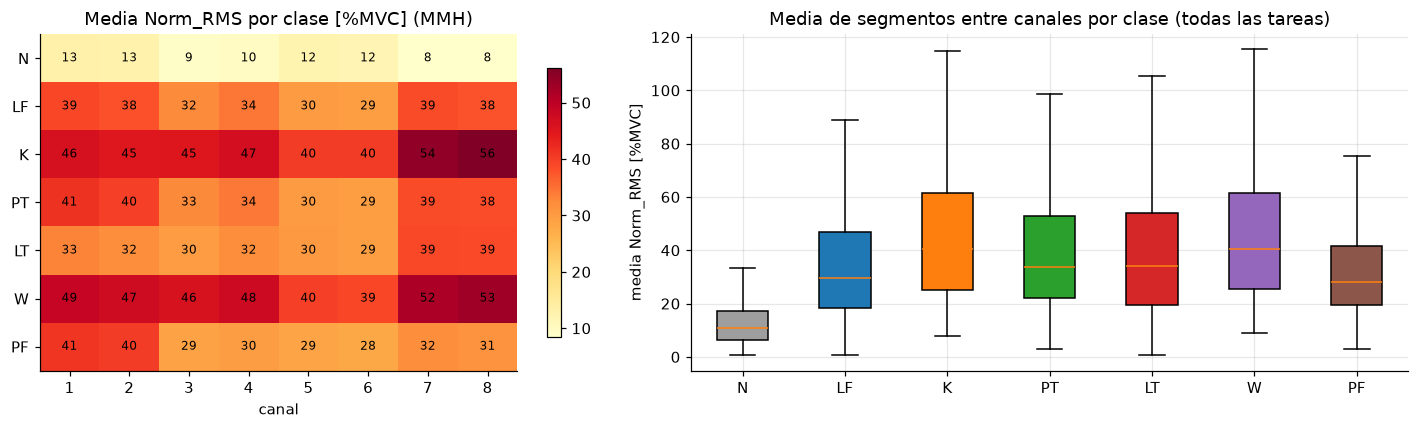

In [29]:
RMS_COLS = [f"rms_{c}" for c in CH]    # Media Norm_RMS por canal y segmento, calculada en scan_emg
# Agregar metadatos y excluir archivos con fallas de señal o etiquetas inconsistentes
seg = seg_stats.merge(emg[["file", "subject", "task", "side", "load_kg", "condition"]], on="file")
seg = seg[~seg.file.isin(BAD_EMG_FILES | BAD_LABEL_FILES)].copy()
seg["rms_mean"] = seg[RMS_COLS].mean(axis=1)    # Media de los 8 canales
print(f"{len(seg)} segmentos utilizados")

fig, axes = plt.subplots(1, 2, figsize=(13, 4), gridspec_kw={"width_ratios": [1, 1.2]})
# Izquierda: media Norm_RMS por clase y canal en ensayos MMH
heat = seg[seg.task.str.startswith("MMH")].groupby("Label")[RMS_COLS].mean().reindex(LABEL_ORDER)
im = axes[0].imshow(heat, cmap="YlOrRd", aspect="auto")
axes[0].set(xticks=range(N_CH), xticklabels=list(CH), yticks=range(7), yticklabels=LABEL_ORDER, xlabel="canal", title="Media Norm_RMS por clase [%MVC] (MMH)")
axes[0].grid(False)
# Escribir el valor de cada celda
for i, j in product(range(7), range(N_CH)):
    axes[0].text(j, i, f"{heat.iloc[i, j]:.0f}", ha="center", va="center", fontsize=8)
fig.colorbar(im, ax=axes[0], shrink=0.8)

# Derecha: distribución por clase de las medias de segmento entre canales, para todas las tareas
data = [seg.loc[seg.Label == l, "rms_mean"] for l in LABEL_ORDER]
bp = axes[1].boxplot(data, tick_labels=LABEL_ORDER, patch_artist=True, showfliers=False)
for patch, l in zip(bp["boxes"], LABEL_ORDER):
    patch.set_facecolor(LABEL_COLORS[l])
axes[1].set(ylabel="media Norm_RMS [%MVC]", title="Media de segmentos entre canales por clase (todas las tareas)")
fig.tight_layout()

La sEMG distingue claramente **reposo y actividad**: `N` se sitúa en ~8–13 %MVC en todos los canales, mientras que las demás clases muestran valores aproximadamente entre 3 y 6 veces mayores. Entre las clases activas (`K` y `W`, las más altas, ~40–55 %MVC; levantamientos y colocaciones, ~30–40 %), las distribuciones se superponen considerablemente. Esto sugiere que la sEMG por sí sola no basta para distinguirlas y que conviene combinarla con los datos de movimiento.

Efecto de la carga en los ensayos bimanuales, promediando los canales:


Label,N,LF,K,PT,LT,W,PF
load_kg,,,,,,,
2.0,9,20,22,23,19,22,21
8.0,10,37,53,39,32,51,34
12.0,12,50,75,47,45,73,43


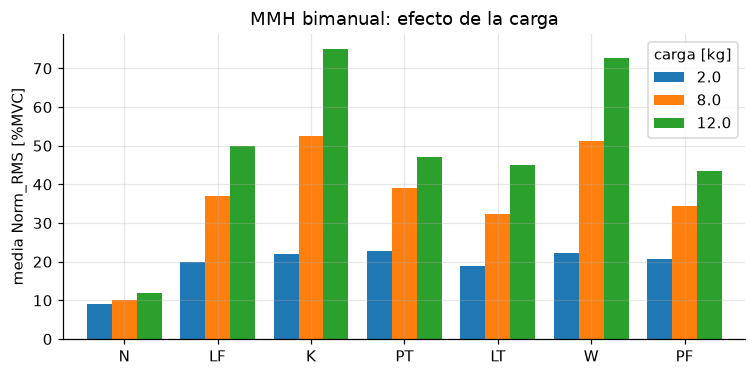

In [30]:
# Media Norm_RMS por clase (filas) y carga (columnas), solo MMH bimanual
bim = seg[seg.task == "MMH_Bim"].groupby(["Label", "load_kg"]).rms_mean.mean().unstack()
# Conservar el orden de las clases presentes
bim = bim.reindex([l for l in LABEL_ORDER if l in bim.index])
ax = bim.plot.bar(rot=0, figsize=(8, 3.6), width=0.8)
ax.set(ylabel="media Norm_RMS [%MVC]", xlabel="", title="MMH bimanual: efecto de la carga"); ax.legend(title="carga [kg]")
# Mostrar los mismos valores redondeados, con cargas en las filas
bim.round(0).astype(int).T

La amplitud aumenta de forma monótona con la carga en todas las clases activas (en `K` y `W` se triplica aproximadamente entre 2 y 12 kg), mientras que en reposo (`N`) apenas cambia. Por tanto, la sEMG aporta información para la **estimación de carga**, uno de los usos previstos del conjunto, y el efecto de la carga es tan grande como las diferencias entre clases activas.


# 9. Captura de movimiento (MVNX)

Los registros de movimiento complementan la activación muscular explorada anteriormente: describen **dónde se mueve el cuerpo**, mientras que la sEMG describe su actividad muscular. Seguimos la misma secuencia que para sEMG: inventario, características de las grabaciones, etiquetas, calidad de las señales, ensayos de ejemplo y resúmenes por actividad.

Existen dos carpetas de anotaciones. `Labels/` indexa las muestras sEMG; **`Labels 2/` indexa los frames MVNX**. Por ello, el movimiento puede explorarse con sus propias etiquetas sin alinear primero los relojes de adquisición. La fusión con sEMG sí requiere una comprobación independiente de la alineación (sección 9.7).

### 9.1. Estructura de archivos e inventario de anotaciones

Un archivo MVNX es XML con un espacio de nombres, una definición del modelo corporal y una secuencia de frames. Las poses de calibración (`identity`, `tpose`, `tpose-isb`) no son muestras de la grabación: solo los frames con `type="normal"` se incluyen en los análisis siguientes. Los nombres y las dimensiones se leen del XML, en lugar de inferirse a partir de un número fijo de canales.


In [31]:
# Un archivo de etiquetas por MVNX; MMH_Bim no usa sufijo L/R en ninguna de las dos carpetas
mocap["label_path"] = [
    MVNX_LABEL_DIR / f"Subj_{s:02d}" / f"{p.stem}_mvnx_labels.csv"
    for s, p in zip(mocap.subject, mocap.path)
]
expected_mv_labels = set(mocap.label_path)
found_mv_labels = set(MVNX_LABEL_DIR.glob("Subj_*/*.csv"))
print(f"MVNX: {len(mocap)} archivos, {mocap.subject.nunique()} sujetos")
print("Archivos de etiquetas faltantes:", len(expected_mv_labels - found_mv_labels))
print("Archivos de etiquetas sin MVNX correspondiente:", len(found_mv_labels - expected_mv_labels))
assert expected_mv_labels == found_mv_labels, "Revisar el inventario MVNX / Labels 2 antes de continuar"
assert not mocap.file.duplicated().any(), "Hay nombres de archivo MVNX duplicados"

NS = "{http://www.xsens.com/mvn/mvnx}"


def read_mvnx_header(path):
    """Leer nombres del modelo corporal, metadatos y campos del primer frame normal."""
    header = {k: [] for k in ("segments", "sensors", "joints", "ergonomic", "contacts", "calibration")}
    names = {"segment": "segments", "sensor": "sensors", "joint": "joints",
             "ergonomicJointAngle": "ergonomic", "contactDefinition": "contacts"}
    with open(path, "rb") as fh:
        for event, el in ET.iterparse(fh, events=("start", "end")):
            tag = el.tag.rsplit("}", 1)[-1]
            if event == "start" and tag == "subject":
                header["subject"] = dict(el.attrib)
            elif event == "start" and tag == "frames":
                header["frames"] = dict(el.attrib)
            elif event == "end" and tag in names and el.get("label"):
                header[names[tag]].append(el.get("label"))
            elif event == "end" and tag == "frame":
                if el.get("type") == "normal":
                    header["first_frame"] = dict(el.attrib)
                    header["fields"] = {c.tag.rsplit("}", 1)[-1]: len((c.text or "").split()) for c in el}
                    return header
                header["calibration"].append(el.get("type"))
    raise ValueError(f"No hay frames normales: {path.name}")


example = MVNX_DIR / "Subj_03" / "Subj_03_MMH_Bim_08kg_Trial_2.mvnx"
mv_header = read_mvnx_header(example)    # Mismo ensayo bimanual de la sección 7
print("Frames de calibración:", mv_header["calibration"])
for group in ("segments", "sensors", "joints"):
    print(f"{group} ({len(mv_header[group])}):", ", ".join(mv_header[group]))
pd.Series(mv_header["fields"], name="valores por frame normal").to_frame()

MVNX: 517 archivos, 14 sujetos
Archivos de etiquetas faltantes: 0
Archivos de etiquetas sin MVNX correspondiente: 0
Frames de calibración: ['identity', 'tpose', 'tpose-isb']
segments (23): Pelvis, L5, L3, T12, T8, Neck, Head, RightShoulder, RightUpperArm, RightForeArm, RightHand, LeftShoulder, LeftUpperArm, LeftForeArm, LeftHand, RightUpperLeg, RightLowerLeg, RightFoot, RightToe, LeftUpperLeg, LeftLowerLeg, LeftFoot, LeftToe
sensors (17): Pelvis, T8, Head, RightShoulder, RightUpperArm, RightForeArm, RightHand, LeftShoulder, LeftUpperArm, LeftForeArm, LeftHand, RightUpperLeg, RightLowerLeg, RightFoot, LeftUpperLeg, LeftLowerLeg, LeftFoot
joints (22): jL5S1, jL4L3, jL1T12, jT9T8, jT1C7, jC1Head, jRightT4Shoulder, jRightShoulder, jRightElbow, jRightWrist, jLeftT4Shoulder, jLeftShoulder, jLeftElbow, jLeftWrist, jRightHip, jRightKnee, jRightAnkle, jRightBallFoot, jLeftHip, jLeftKnee, jLeftAnkle, jLeftBallFoot


,valores por frame normal
orientation,92
position,69
velocity,69
acceleration,69
angularVelocity,69
angularAcceleration,69
footContacts,4
sensorFreeAcceleration,51
sensorMagneticField,51
sensorOrientation,68


Cada frame normal de este ejemplo contiene 23 posiciones de segmentos (69 valores), 23 orientaciones de segmentos (92 componentes de cuaterniones), 22 ternas de ángulos articulares (66 valores), 17 orientaciones de sensores, cinemática lineal y angular, seis ternas de ángulos ergonómicos, cuatro indicadores de contacto de los pies y el centro de masa.

| Campo | Dimensiones por frame | Unidad / interpretación |
|---|---|---|
| `position` | segmentos × 3 | Posición global, m |
| `orientation` | segmentos × 4 | Cuaternión unitario, sin unidades |
| `jointAngle` | articulaciones × 3 | Componentes de ángulos de Euler, grados (convención ZXY) |
| `jointAngleXZY` | articulaciones × 3 | Convención de Euler alternativa; mantener separada de `jointAngle` |
| `velocity`, `acceleration` | segmentos × 3 | m/s, m/s² |
| `footContacts` | 4 | 0 / 1 para cada punto de contacto |

Las unidades y convenciones de rotación siguen el [manual de usuario Xsens MVN, exportación MVNX](https://www.movella.com/hubfs/Downloads/Manuals/MVN_User_Manual_v10AR_v02.pdf). Las gráficas conservan la numeración de los componentes exportados; no se asigna el mismo significado anatómico a un componente en todas las articulaciones. Las posiciones usan el sistema de referencia global de la grabación, por lo que las coordenadas absolutas X/Y no deben compararse entre ensayos sin una referencia espacial común.


### 9.2. Características de las grabaciones y lectura secuencial

El siguiente recorrido lee **todos los frames normales de todos los archivos MVNX**, una grabación a la vez. Revisa los índices de frame y ambas marcas de tiempo, la disponibilidad de campos y las dimensiones y valores finitos de `position`, `orientation`, `jointAngle` y `footContacts`. También comprueba las normas de los cuaterniones y los valores binarios de contacto. Los demás campos se incluyen en el inventario, pero aquí no se revisa su calidad numérica.

Por articulación y componente se guardan la mediana y la diferencia entre los percentiles 95 y 5. Por segmento etiquetado válido se guardan las medias del componente angular 3 de codos y rodillas, las alturas de manos y pelvis, la velocidad de la pelvis y la fracción de contactos. Son características descriptivas, con una fila por segmento; no se ajusta ningún clasificador.

La caché incluye un registro de los tamaños y fechas de modificación de los archivos MVNX y sus etiquetas. La primera ejecución lee ~57 GB y puede tardar varios minutos. Las ejecuciones siguientes reutilizan las tablas de resumen si ese registro de archivos sigue coincidiendo.


In [32]:
# Los índices XML comienzan en cero; se interpretan así las etiquetas, como en los ejemplos sEMG
# Los CSV no declaran el origen de sus índices; usar 1 si se confirma que comienzan en uno
# Cambiar el origen desplaza el límite un frame (~4.2 ms a 240 Hz), no varios segundos
MVNX_LABEL_BASE = 0
CORE_FIELDS = ("position", "orientation", "jointAngle", "footContacts")


def read_mvnx_recording(path, header):
    """Leer solo frames normales y conservar en memoria los arreglos seleccionados de una grabación."""
    widths = {"position": 3 * len(header["segments"]), "orientation": 4 * len(header["segments"]),
              "jointAngle": 3 * len(header["joints"]), "footContacts": len(header["contacts"])}
    values = {k: [] for k in CORE_FIELDS}
    attrs, calibration = [], []
    missing, wrong_width = dict.fromkeys(CORE_FIELDS, 0), dict.fromkeys(CORE_FIELDS, 0)
    schema_changes, frames = 0, None
    with open(path, "rb") as fh:
        for event, el in ET.iterparse(fh, events=("start", "end")):
            if event == "start" and el.tag == NS + "frames":
                frames = el
            elif event == "end" and el.tag == NS + "frame":
                if el.get("type") == "normal":
                    attrs.append((int(el.get("index")), float(el.get("time")), int(el.get("ms"))))
                    fields = {c.tag.rsplit("}", 1)[-1]: c for c in el}
                    schema_changes += set(fields) != set(header["fields"])
                    for key in CORE_FIELDS:
                        child = fields.get(key)
                        a = np.fromstring(child.text or "", sep=" ") if child is not None else np.array([])
                        missing[key] += child is None
                        wrong_width[key] += child is not None and a.size != widths[key]
                        # Conservar los frames con dimensiones incorrectas como NaN; el archivo se marca más adelante
                        values[key].append(a if a.size == widths[key] else np.full(widths[key], np.nan))
                else:
                    calibration.append(el.get("type"))
                frames.remove(el)    # Liberar cada frame XML y sus elementos hijos
    if not attrs:
        raise ValueError(f"No hay frames normales: {path.name}")
    data = {k: np.asarray(v) for k, v in values.items()}
    data["index"], data["time_ms"], data["epoch_ms"] = np.asarray(attrs).T
    checks = {"schema_changes": schema_changes, "n_calibration": len(calibration),
              "calibration_types": " / ".join(calibration)}
    for key in CORE_FIELDS:
        checks.update({f"missing_{key}": missing[key], f"width_{key}": wrong_width[key],
                       f"nonfinite_{key}": int((~np.isfinite(data[key])).sum())})
    return data, checks


def mvnx_features(data, header, side):
    # Usar el lado de la tarea en ensayos unilaterales/isocinéticos y ambos lados en bimanuales
    joints = {n: i for i, n in enumerate(header["joints"])}
    segments = {n: i for i, n in enumerate(header["segments"])}
    sides = ["Left"] if side == "L" else ["Right"] if side == "R" else ["Left", "Right"]
    a = data["jointAngle"].reshape(-1, len(joints), 3)
    p = data["position"].reshape(-1, len(segments), 3)
    pelvis = p[:, segments["Pelvis"]]
    dt = np.diff(data["time_ms"]) / 1000
    speed = np.full(len(p), np.nan)
    np.divide(np.linalg.norm(np.diff(pelvis, axis=0), axis=1), dt, out=speed[1:], where=dt > 0)
    return pd.DataFrame({
        "elbow_c3_deg": a[:, [joints[f"j{s}Elbow"] for s in sides], 2].mean(axis=1),
        "knee_c3_deg": a[:, [joints[f"j{s}Knee"] for s in sides], 2].mean(axis=1),
        "hand_z_m": p[:, [segments[f"{s}Hand"] for s in sides], 2].mean(axis=1),
        "pelvis_z_m": pelvis[:, 2], "pelvis_speed_m_s": speed,
        "contact_frac": data["footContacts"].mean(axis=1),
    })


def scan_mvnx(row):
    header = read_mvnx_header(row.path)
    data, checks = read_mvnx_recording(row.path, header)
    rate, n = float(header["subject"]["frameRate"]), len(data["index"])
    dt, dt_epoch = np.diff(data["time_ms"]), np.diff(data["epoch_ms"])
    quats = data["orientation"].reshape(n, -1, 4)
    q_error = np.abs(np.linalg.norm(quats, axis=2) - 1)
    contacts = data["footContacts"]
    signature = {k: header[k] for k in ("segments", "sensors", "joints", "ergonomic", "contacts", "fields")}
    stats = dict(file=row.file, frame_rate=rate, n_frames=n,
                 duration_s=(data["time_ms"][-1] - data["time_ms"][0]) / 1000,
                 sample_span_s=n / rate, ms0=data["epoch_ms"][0], ms1=data["epoch_ms"][-1],
                 size_mb=row.path.stat().st_size / 1e6,
                 n_segments=len(header["segments"]), n_sensors=len(header["sensors"]), n_joints=len(header["joints"]),
                 configuration=header["subject"].get("configuration"),
                 model_signature=hashlib.sha256(json.dumps(signature, sort_keys=True).encode()).hexdigest(),
                 index_errors=int((data["index"][0] != 0) + np.count_nonzero(np.diff(data["index"]) != 1)),
                 n_nonmono=int((dt <= 0).sum()), epoch_nonmono=int((dt_epoch <= 0).sum()),
                 dt_min_ms=dt.min(), dt_max_ms=dt.max(),
                 # Las marcas enteras en ms redondean un periodo de 4.167 ms a 4 o 5 ms
                 n_time_gaps=int((dt > 1000 / rate + 1.1).sum()),
                 n_epoch_gaps=int((dt_epoch > 1000 / rate + 1.1).sum()),
                 clock_span_error_ms=float(abs((data["epoch_ms"][-1] - data["epoch_ms"][0]) - (data["time_ms"][-1] - data["time_ms"][0]))),
                 q_norm_max_error=float(np.nanmax(q_error)),
                 q_norm_bad=int((q_error > 1e-3).sum()),
                 contact_nonbinary=int((~np.isin(contacts, [0, 1])).sum()), **checks)
    # Variación robusta de los ángulos exportados; no representa un diagnóstico de movilidad anatómica
    angles = data["jointAngle"].reshape(n, -1, 3)
    p05, med, p95 = np.nanpercentile(angles, [5, 50, 95], axis=0)
    joint_rows = [dict(file=row.file, joint=name, component=c + 1,
                       median_deg=med[j, c], spread_deg=p95[j, c] - p05[j, c])
                  for j, name in enumerate(header["joints"]) for c in range(3)]
    # Los archivos con anotaciones inválidas o superpuestas no aportan medias por segmento
    features = mvnx_features(data, header, row.side)
    labels = pd.read_csv(row.label_path)
    start, end = labels.Start_Frame - MVNX_LABEL_BASE, labels.End_Frame - MVNX_LABEL_BASE
    bad = ((start < 0) | (end < start) | (end >= n) | ~labels.Label.isin(LABEL_ORDER)
           | (start <= end.shift(1)))
    seg_rows = []
    if not bad.any():
        for i, (s0, s1, label) in enumerate(zip(start, end, labels.Label)):
            means = features.iloc[int(s0):int(s1) + 1].mean().to_dict()
            seg_rows.append(dict(file=row.file, seg=i, Label=label, **means))
    return stats, joint_rows, seg_rows

In [33]:
MV_CACHE = CACHE_DIR / "mvnx_v2"
MV_CACHE.mkdir(exist_ok=True)
MV_FILE_CSV, MV_JOINT_CSV, MV_SEG_CSV = [MV_CACHE / n for n in ("file_stats.csv", "joint_stats.csv", "segment_stats.csv")]
MV_MANIFEST = MV_CACHE / "manifest.json"
# La versión invalida la caché si cambia el cálculo o la convención de índices
source_paths = sorted(list(mocap.path) + list(mocap.label_path))
manifest = {"version": 1, "label_base": MVNX_LABEL_BASE, "sources": [
    [str(p.relative_to(ROOT)), p.stat().st_size, p.stat().st_mtime_ns] for p in source_paths
]}
cache_ok = all(p.exists() for p in (MV_FILE_CSV, MV_JOINT_CSV, MV_SEG_CSV, MV_MANIFEST))
if cache_ok:
    cache_ok = json.loads(MV_MANIFEST.read_text()) == manifest

t0 = time.time()
if cache_ok and not REFRESH:
    mv_stats, mv_joint_stats, mv_seg_stats = [pd.read_csv(p) for p in (MV_FILE_CSV, MV_JOINT_CSV, MV_SEG_CSV)]
    print("Se reutilizó la caché MVNX (sin cambios en los archivos de origen)")
else:
    file_rows, joint_rows, segment_rows = [], [], []
    for i, row in enumerate(mocap.itertuples(), 1):
        try:
            st, js, ss = scan_mvnx(row)
        except Exception as exc:
            raise RuntimeError(f"Error durante el recorrido MVNX: {row.file}") from exc
        file_rows.append(st); joint_rows += js; segment_rows += ss
        if i % 25 == 0 or i == len(mocap):
            print(f"{i}/{len(mocap)} archivos, {time.time() - t0:.0f} s")
    mv_stats, mv_joint_stats, mv_seg_stats = map(pd.DataFrame, (file_rows, joint_rows, segment_rows))
    for table, path in zip((mv_stats, mv_joint_stats, mv_seg_stats), (MV_FILE_CSV, MV_JOINT_CSV, MV_SEG_CSV)):
        table.to_csv(path, index=False)
    MV_MANIFEST.write_text(json.dumps(manifest), encoding="utf-8")

assert set(mv_stats.file) == set(mocap.file) and not mv_stats.file.duplicated().any()
mocap = mocap.merge(mv_stats, on="file", validate="one_to_one")
mocap["fs_effective_hz"] = (mocap.n_frames - 1) / mocap.duration_s
print(f"Resúmenes MVNX disponibles en {time.time() - t0:.0f} s: {mocap.n_frames.sum() / 1e6:.2f} millones de frames normales, "
      f"{mocap.sample_span_s.sum() / 3600:.2f} h, {mocap.size_mb.sum() / 1000:.1f} GB")
display(mocap[["n_frames", "duration_s", "frame_rate", "fs_effective_hz", "size_mb"]].describe().round(2))
mocap.groupby("task").agg(files=("file", "size"), hours=("sample_span_s", lambda s: s.sum() / 3600),
                         median_s=("duration_s", "median"), min_s=("duration_s", "min"), max_s=("duration_s", "max")).round(2)

Se reutilizó la caché MVNX (sin cambios en los archivos de origen)
Resúmenes MVNX disponibles en 0 s: 7.12 millones de frames normales, 8.24 h, 56.7 GB


,n_frames,duration_s,frame_rate,fs_effective_hz,size_mb
count,517.00,517.00,517.0,517.00,517.00
mean,13775.26,57.34,240.0,240.22,109.67
std,3983.55,16.59,0.0,0.51,31.16
min,3085.00,12.85,240.0,239.99,24.78
25%,12166.00,50.69,240.0,240.00,97.62
50%,14091.00,58.54,240.0,240.00,112.31
75%,16039.00,66.82,240.0,240.01,127.09
max,29222.00,121.75,240.0,241.83,226.80


,files,hours,median_s,min_s,max_s
task,,,,,
Isokin,223,2.82,49.79,12.85,76.00
MMH_Bim,126,2.32,64.50,49.01,121.75
MMH_One,168,3.10,65.61,45.40,120.44


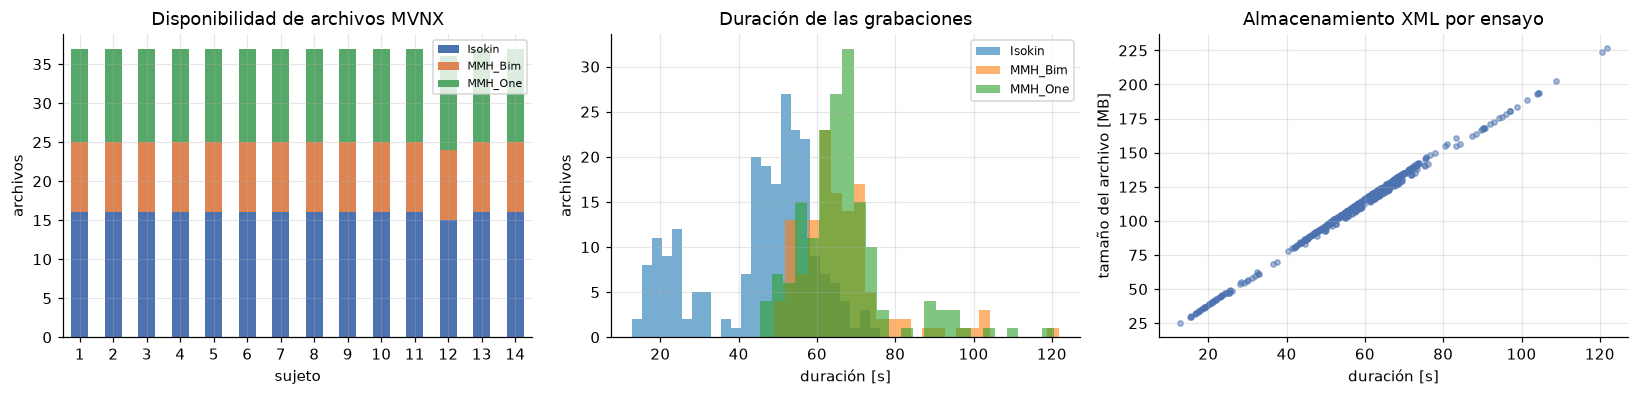

In [34]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.7))
# Izquierda: conteo de ensayos, haciendo visibles los sujetos o tareas faltantes
mv_counts = pd.crosstab(mocap.subject, mocap.task).reindex(range(1, 15), fill_value=0)
mv_counts.plot.bar(ax=axes[0], stacked=True, rot=0, color=["#4c72b0", "#dd8452", "#55a868"])
axes[0].set(xlabel="sujeto", ylabel="archivos", title="Disponibilidad de archivos MVNX")
axes[0].legend(fontsize=7)
for task, g in mocap.groupby("task"):
    axes[1].hist(g.duration_s, bins=25, alpha=0.6, label=task)
axes[1].set(xlabel="duración [s]", ylabel="archivos", title="Duración de las grabaciones")
axes[1].legend(fontsize=8)
axes[2].scatter(mocap.duration_s, mocap.size_mb, s=12, alpha=0.5, color="#4c72b0")
axes[2].set(xlabel="duración [s]", ylabel="tamaño del archivo [MB]", title="Almacenamiento XML por ensayo")
fig.tight_layout()

subject,1,2,3,4,5,6,7,8,9,10,11,12,13,14
min,240.000,240.000,239.992,241.105,239.994,239.999,240.001,239.995,239.998,239.994,239.998,241.424,240.000,240.000
median,240.004,240.004,240.003,241.110,240.004,240.004,240.004,240.004,240.004,240.004,240.004,241.430,240.004,240.004
max,240.010,240.009,240.007,241.114,240.008,240.008,240.010,240.007,240.008,240.009,240.008,241.436,241.830,240.013


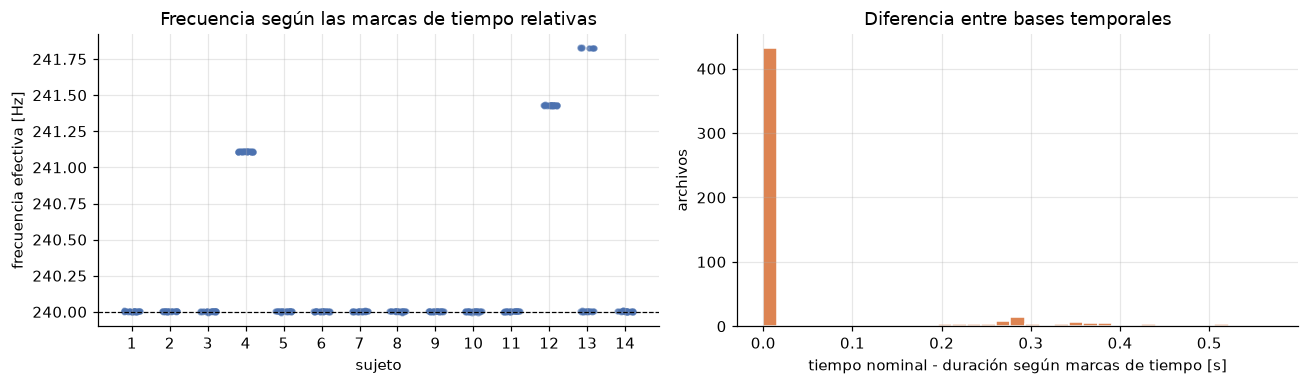

In [35]:
# La frecuencia nominal y la calculada con marcas de tiempo son cantidades distintas
fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
rng_mv = np.random.default_rng(0)
axes[0].scatter(mocap.subject + rng_mv.uniform(-0.22, 0.22, len(mocap)), mocap.fs_effective_hz,
                s=9, alpha=0.5, color="#4c72b0")
axes[0].axhline(240, color="k", ls="--", lw=0.8)
axes[0].set(xlabel="sujeto", ylabel="frecuencia efectiva [Hz]", xticks=range(1, 15), title="Frecuencia según las marcas de tiempo relativas")
nominal_elapsed = (mocap.n_frames - 1) / mocap.frame_rate
axes[1].hist(nominal_elapsed - mocap.duration_s, bins=35, color="#dd8452", edgecolor="white")
axes[1].set(xlabel="tiempo nominal - duración según marcas de tiempo [s]", ylabel="archivos", title="Diferencia entre bases temporales")
fig.tight_layout()
mocap.groupby("subject").fs_effective_hz.agg(["min", "median", "max"]).round(3).T

Los conteos pueden compararse con el diseño esperado de la sección 2: 16 grabaciones isocinéticas, 9 bimanuales y 12 unilaterales por sujeto. El movimiento bimanual se cuenta una sola vez, aunque después se empareje con dos registros sEMG.

`duration_s` es el tiempo transcurrido entre la primera y la última muestra, igual que en la definición sEMG de la sección 4. `sample_span_s = n_frames / frame_rate` incluye un intervalo de muestreo nominal por frame y se usa al sumar las horas registradas o las fracciones etiquetadas. Con un reloj uniforme a la frecuencia declarada, ambas definiciones difieren en un periodo de frame; las marcas de tiempo permiten comprobar ese supuesto.

Todas las cabeceras declaran 240 Hz, pero la frecuencia efectiva calculada con las marcas de tiempo es de aproximadamente 241.11 Hz para el sujeto 4 y 241.43 Hz para el sujeto 12; una grabación del sujeto 13 alcanza 241.83 Hz. Por tanto, las duraciones nominales y las calculadas con marcas de tiempo pueden diferir en más de un frame. Las duraciones de las anotaciones que se presentan abajo usan la **base temporal nominal de frames**; las gráficas de ejemplo y la velocidad derivada de posiciones usan las marcas de tiempo exportadas. El procesamiento para fusionar modalidades debe revisar esta diferencia y usar las coordenadas temporales reales, en lugar de suponer un reloj uniforme de 240 Hz.


### 9.3. Etiquetas de actividad propias de MVNX (Labels 2/)

Se reutilizan las siete clases y los colores de la sección 5. `End_Frame` es inclusivo. Antes de calcular las duraciones por clase se revisan etiquetas faltantes o desconocidas, límites no enteros, intervalos invertidos, índices fuera de la grabación, orden y superposiciones. Al igual que en el análisis sEMG, **se excluye el archivo completo de anotaciones** de los resúmenes por actividad si algún segmento no cumple estas comprobaciones.

Los CSV no declaran explícitamente si los índices de frame comienzan en cero o en uno. Los cálculos usan `MVNX_LABEL_BASE = 0`, de acuerdo con los índices XML y la convención de selección de muestras usada anteriormente; es un supuesto explícito que debe verificarse antes de preparar ventanas de entrenamiento. Las poses de calibración se excluyen en cualquiera de las dos convenciones.


In [36]:
mv_lab = pd.concat([pd.read_csv(r.label_path).assign(file=r.file) for r in mocap.itertuples()], ignore_index=True)
mv_lab = mv_lab.merge(mocap[["file", "subject", "task", "side", "load_kg", "condition", "n_frames", "frame_rate"]],
                      on="file", validate="many_to_one")
mv_lab["seg"] = mv_lab.groupby("file").cumcount()
mv_lab["start_idx"] = mv_lab.Start_Frame - MVNX_LABEL_BASE
mv_lab["end_idx"] = mv_lab.End_Frame - MVNX_LABEL_BASE
mv_lab["seg_frames"] = mv_lab.end_idx - mv_lab.start_idx + 1
mv_lab["seg_s"] = mv_lab.seg_frames / mv_lab.frame_rate
mv_lab["gap_to_next"] = mv_lab.groupby("file").start_idx.shift(-1) - mv_lab.end_idx - 1
mv_lab["bad_boundary"] = (mv_lab[["start_idx", "end_idx"]].isna().any(axis=1)
                          | (mv_lab.start_idx % 1 != 0) | (mv_lab.end_idx % 1 != 0)
                          | (mv_lab.start_idx < 0) | (mv_lab.end_idx >= mv_lab.n_frames)
                          | (mv_lab.seg_frames <= 0))
mv_lab["bad_label"] = ~mv_lab.Label.isin(LABEL_ORDER)
mv_lab["bad_order"] = mv_lab.groupby("file").start_idx.diff() < 0
mv_lab["overlap_next"] = mv_lab.gap_to_next < 0    # Cero significa continuidad entre segmentos, sin superposición
bad_mv_labels = mv_lab[mv_lab[["bad_boundary", "bad_label", "bad_order", "overlap_next"]].any(axis=1)]
BAD_MV_LABEL_FILES = set(bad_mv_labels.file)
mv_valid = mv_lab[~mv_lab.file.isin(BAD_MV_LABEL_FILES)].copy()
print(f"{len(mv_lab)} segmentos en {mv_lab.file.nunique()} archivos de anotaciones MVNX")
print(f"Marcados para revisión: {len(bad_mv_labels)} segmentos en {len(BAD_MV_LABEL_FILES)} archivos")
display(bad_mv_labels[["file", "seg", "Start_Frame", "End_Frame", "Label", "gap_to_next", "bad_boundary", "bad_order", "overlap_next"]])
display(mv_valid.groupby(["task", "Label"]).size().unstack(fill_value=0).reindex(columns=LABEL_ORDER, fill_value=0))
assert (mv_valid.seg_frames > 0).all() and (mv_valid.end_idx < mv_valid.n_frames).all()

8337 segmentos en 517 archivos de anotaciones MVNX
Marcados para revisión: 11 segmentos en 2 archivos


,file,seg,Start_Frame,End_Frame,Label,gap_to_next,bad_boundary,bad_order,overlap_next
1122,Subj_02_MMH_One_R_02kg_Trial_2.mvnx,0,525,981,N,-457.0,False,False,True
1123,Subj_02_MMH_One_R_02kg_Trial_2.mvnx,1,525,1503,LF,-522.0,False,False,True
1124,Subj_02_MMH_One_R_02kg_Trial_2.mvnx,2,982,2125,K,-622.0,False,False,True
1125,Subj_02_MMH_One_R_02kg_Trial_2.mvnx,3,1504,2656,PT,-531.0,False,False,True
1126,Subj_02_MMH_One_R_02kg_Trial_2.mvnx,4,2126,3270,N,-614.0,False,False,True
1127,Subj_02_MMH_One_R_02kg_Trial_2.mvnx,5,2657,3667,LT,-397.0,False,False,True
1128,Subj_02_MMH_One_R_02kg_Trial_2.mvnx,6,3271,5874,W,-2207.0,False,False,True
1130,Subj_02_MMH_One_R_02kg_Trial_2.mvnx,8,5875,5531,N,-521.0,True,False,True
1131,Subj_02_MMH_One_R_02kg_Trial_2.mvnx,9,5011,6108,LF,-577.0,False,True,True
1132,Subj_02_MMH_One_R_02kg_Trial_2.mvnx,10,5532,6578,PT,-470.0,False,False,True


Label,N,LF,K,PT,LT,W,PF
task,,,,,,,
Isokin,1101,0,56,879,879,0,0
MMH_Bim,717,353,126,353,242,242,242
MMH_One,985,490,167,490,329,329,329


Label,N,LF,K,PT,LT,W,PF
segments,2803.00,843.00,349.00,1722.00,1450.00,571.00,571.00
hours,3.01,0.59,0.54,1.04,0.66,0.47,0.45
median_s,3.71,2.42,4.38,2.14,1.56,3.02,2.79
share_%,44.46,8.77,8.03,15.42,9.75,6.99,6.58


,labeled_frac,lead_s,tail_s
count,515.00,515.00,515.00
mean,0.81,5.12,4.99
std,0.13,3.77,5.54
min,0.19,0.21,0.05
25%,0.76,2.55,2.46
50%,0.84,4.17,3.82
75%,0.90,6.61,5.34
max,0.99,37.50,37.49


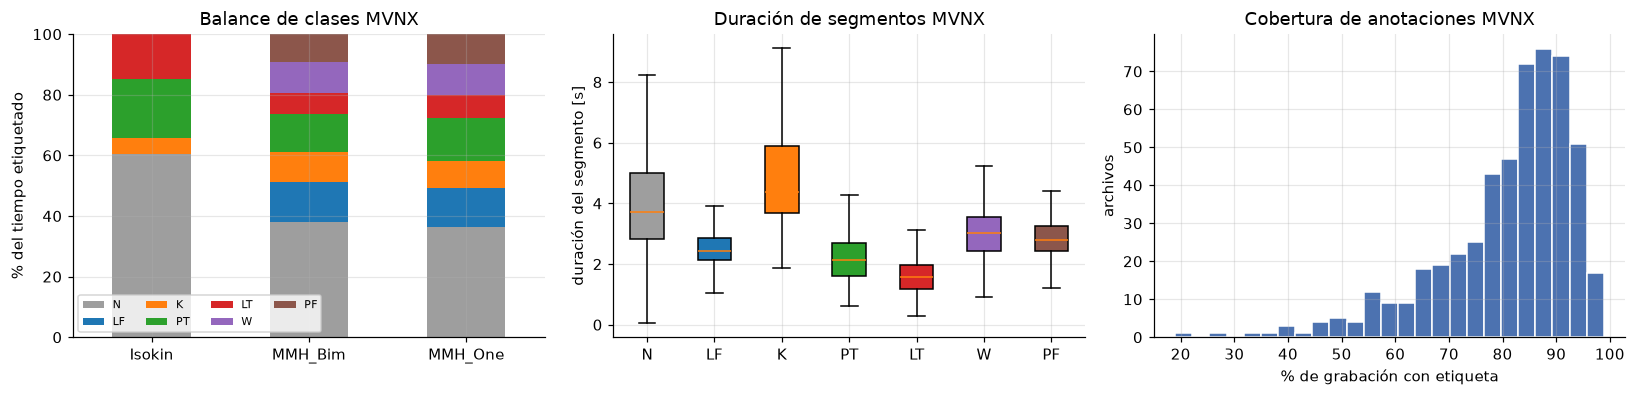

In [37]:
# La cobertura solo usa anotaciones válidas; ninguna muestra sin etiqueta se asigna a N
mv_cov = mv_valid.groupby("file").agg(first=("start_idx", "min"), last=("end_idx", "max"),
                                      labeled=("seg_frames", "sum"), n_frames=("n_frames", "first"),
                                      rate=("frame_rate", "first"))
mv_cov["labeled_frac"] = mv_cov.labeled / mv_cov.n_frames
mv_cov["lead_s"] = mv_cov["first"] / mv_cov.rate
mv_cov["tail_s"] = (mv_cov.n_frames - 1 - mv_cov["last"]) / mv_cov.rate
assert mv_cov.labeled_frac.between(0, 1).all()

fig, axes = plt.subplots(1, 3, figsize=(15, 3.7))
mv_time = mv_valid.pivot_table(index="task", columns="Label", values="seg_s", aggfunc="sum", fill_value=0).reindex(columns=LABEL_ORDER, fill_value=0)
(mv_time.div(mv_time.sum(axis=1), axis=0) * 100).plot.bar(stacked=True, ax=axes[0], rot=0,
    color=[LABEL_COLORS[l] for l in LABEL_ORDER])
axes[0].set(ylabel="% del tiempo etiquetado", xlabel="", title="Balance de clases MVNX")
axes[0].legend(fontsize=7, ncol=4)
bp = axes[1].boxplot([mv_valid.loc[mv_valid.Label == l, "seg_s"] for l in LABEL_ORDER],
                     tick_labels=LABEL_ORDER, patch_artist=True, showfliers=False)
for patch, label in zip(bp["boxes"], LABEL_ORDER):
    patch.set_facecolor(LABEL_COLORS[label])
axes[1].set(ylabel="duración del segmento [s]", title="Duración de segmentos MVNX")
axes[2].hist(mv_cov.labeled_frac * 100, bins=25, color="#4c72b0", edgecolor="white")
axes[2].set(xlabel="% de grabación con etiqueta", ylabel="archivos", title="Cobertura de anotaciones MVNX")
fig.tight_layout()

mv_class = mv_valid.groupby("Label").agg(segments=("seg", "size"), hours=("seg_s", lambda s: s.sum() / 3600), median_s=("seg_s", "median")).reindex(LABEL_ORDER)
mv_class["share_%"] = mv_class.hours / mv_class.hours.sum() * 100
display(mv_class.round(2).T)
mv_cov[["labeled_frac", "lead_s", "tail_s"]].describe().round(2)

Después de excluir 2 archivos de anotaciones inconsistentes, quedan **8,309 segmentos** en 515 grabaciones, con **6.77 horas etiquetadas sobre la base temporal nominal de frames**. La mediana de la fracción etiquetada es 84.3 % y `N` representa el 44.5 % del tiempo etiquetado.

La tabla de anotaciones propias de MVNX permite identificar las exclusiones y los márgenes sin etiqueta, sin transferir índices desde sEMG. También aparece un intervalo invertido en el ensayo unilateral del sujeto 2, y el ensayo isocinético del sujeto 5 termina con un intervalo `N` invertido. La revisión considera los límites compartidos como superposiciones, porque dos intervalos inclusivos no deben usar la misma muestra.

El balance de clases debe calcularse por separado para cada modalidad. En particular, contar ambos brazos sEMG en los ensayos bimanuales duplica la secuencia de actividad, mientras que MVNX aporta una sola secuencia. Las diferencias en márgenes sin etiqueta y límites de anotación también pueden cambiar el total de horas etiquetadas.


### 9.4. Calidad de las señales de movimiento

Se distingue una grabación con errores de estructura de un movimiento de gran amplitud, pero finito. Los problemas estructurales, valores no finitos en los campos principales, índices de frame discontinuos, intervalos temporales anómalos, cuaterniones no unitarios o contactos de pies no binarios marcan el archivo para revisión. La tolerancia de `1e-3` para la norma del cuaternión es una comprobación numérica, no una estimación de la exactitud de la captura.


In [38]:
mv_error_cols = [f"{prefix}_{field}" for field in CORE_FIELDS for prefix in ("missing", "width", "nonfinite")]
mv_error_cols += ["schema_changes", "index_errors", "n_nonmono", "epoch_nonmono", "n_time_gaps", "n_epoch_gaps", "q_norm_bad", "contact_nonbinary"]
print("Conteos de incidencias en campos principales y tiempo:")
display(pd.DataFrame({prefix: [mocap[f"{prefix}_{field}"].sum() for field in CORE_FIELDS]
                      for prefix in ("missing", "width", "nonfinite")}, index=CORE_FIELDS))
display(mocap[[c for c in mv_error_cols if c not in [f"{p}_{f}" for f in CORE_FIELDS for p in ("missing", "width", "nonfinite")]]].sum().rename("conteo").to_frame())
print("Variantes del modelo corporal y sus campos:", mocap.model_signature.nunique())
print("Conteos de frames de calibración:", mocap.n_calibration.value_counts().to_dict())
print("Tipos de calibración:", mocap.calibration_types.unique().tolist())
print("Frecuencias de frames [Hz]:", sorted(mocap.frame_rate.unique()))
print(f"Mayor error de norma de cuaternión: {mocap.q_norm_max_error.max():.2g}")
print(f"Mayor diferencia entre duraciones de relojes relativo / Unix: {mocap.clock_span_error_ms.max():.1f} ms")
BAD_MV_SIGNAL_FILES = set(mocap.loc[(mocap[mv_error_cols] > 0).any(axis=1) | (mocap.clock_span_error_ms > 2), "file"])
print(f"Archivos de señal MVNX marcados para revisión: {len(BAD_MV_SIGNAL_FILES)}")
flag_columns = [c for c in mv_error_cols if (mocap[c] > 0).any()]
display(mocap.loc[mocap.file.isin(BAD_MV_SIGNAL_FILES), ["file", "clock_span_error_ms"] + flag_columns])
variant_rows = []
for signature, group in mocap.groupby("model_signature"):
    h = read_mvnx_header(group.path.iloc[0])
    variant_rows.append(dict(files=len(group), subjects=", ".join(map(str, sorted(group.subject.unique()))),
                             ergonomic_angles=len(h["ergonomic"]), jointAngleErgoXZY="jointAngleErgoXZY" in h["fields"]))
display(pd.DataFrame(variant_rows))
mocap[["dt_min_ms", "dt_max_ms", "q_norm_max_error", "n_segments", "n_sensors", "n_joints"]].describe().round(6)

Conteos de incidencias en campos principales y tiempo:


,missing,width,nonfinite
position,0,0,0
orientation,0,0,0
jointAngle,0,0,0
footContacts,0,0,0


,conteo
schema_changes,0
index_errors,0
n_nonmono,0
epoch_nonmono,0
n_time_gaps,14
n_epoch_gaps,14
q_norm_bad,0
contact_nonbinary,0


Variantes del modelo corporal y sus campos: 2
Conteos de frames de calibración: {3: 517}
Tipos de calibración: ['identity / tpose / tpose-isb']
Frecuencias de frames [Hz]: [np.float64(240.0)]
Mayor error de norma de cuaternión: 9.8e-07
Mayor diferencia entre duraciones de relojes relativo / Unix: 0.0 ms
Archivos de señal MVNX marcados para revisión: 7


,file,clock_span_error_ms,n_time_gaps,n_epoch_gaps
212,Subj_06_MMH_One_L_02kg_Trial_3.mvnx,0.0,2,2
251,Subj_07_MMH_One_L_04kg_Trial_2.mvnx,0.0,1,1
329,Subj_09_MMH_One_R_02kg_Trial_3.mvnx,0.0,3,3
381,Subj_11_Isokin_R_02kg_St.mvnx,0.0,1,1
472,Subj_13_MMH_One_L_04kg_Trial_2.mvnx,0.0,4,4
481,Subj_14_Isokin_L_02kg_60bpm.mvnx,0.0,1,1
496,Subj_14_MMH_Bim_02kg_Trial_1.mvnx,0.0,2,2


,files,subjects,ergonomic_angles,jointAngleErgoXZY
0,406,"2, 3, 4, 5, 6, 7, 8, 9, 10, 12, 14",6,True
1,111,"1, 11, 13",4,False


,dt_min_ms,dt_max_ms,q_norm_max_error,n_segments,n_sensors,n_joints
count,517.000000,517.000000,517.000000,517.0,517.0,517.0
mean,3.796905,5.013540,0.000001,23.0,17.0,22.0
std,0.407476,0.115682,0.000000,0.0,0.0,0.0
min,2.000000,5.000000,0.000001,23.0,17.0,22.0
25%,4.000000,5.000000,0.000001,23.0,17.0,22.0
50%,4.000000,5.000000,0.000001,23.0,17.0,22.0
75%,4.000000,5.000000,0.000001,23.0,17.0,22.0
max,4.000000,6.000000,0.000001,23.0,17.0,22.0


,max_spread_deg
file,
Subj_12_MMH_One_L_04kg_Trial_1.mvnx,358.8
Subj_02_MMH_One_L_04kg_Trial_3.mvnx,152.2
Subj_02_MMH_One_L_02kg_Trial_1.mvnx,151.3
Subj_02_MMH_One_L_02kg_Trial_3.mvnx,150.8
Subj_02_MMH_One_R_02kg_Trial_1.mvnx,149.7
Subj_02_MMH_One_L_02kg_Trial_2.mvnx,149.2
Subj_02_MMH_One_L_04kg_Trial_1.mvnx,147.8
Subj_02_MMH_One_L_04kg_Trial_2.mvnx,146.0


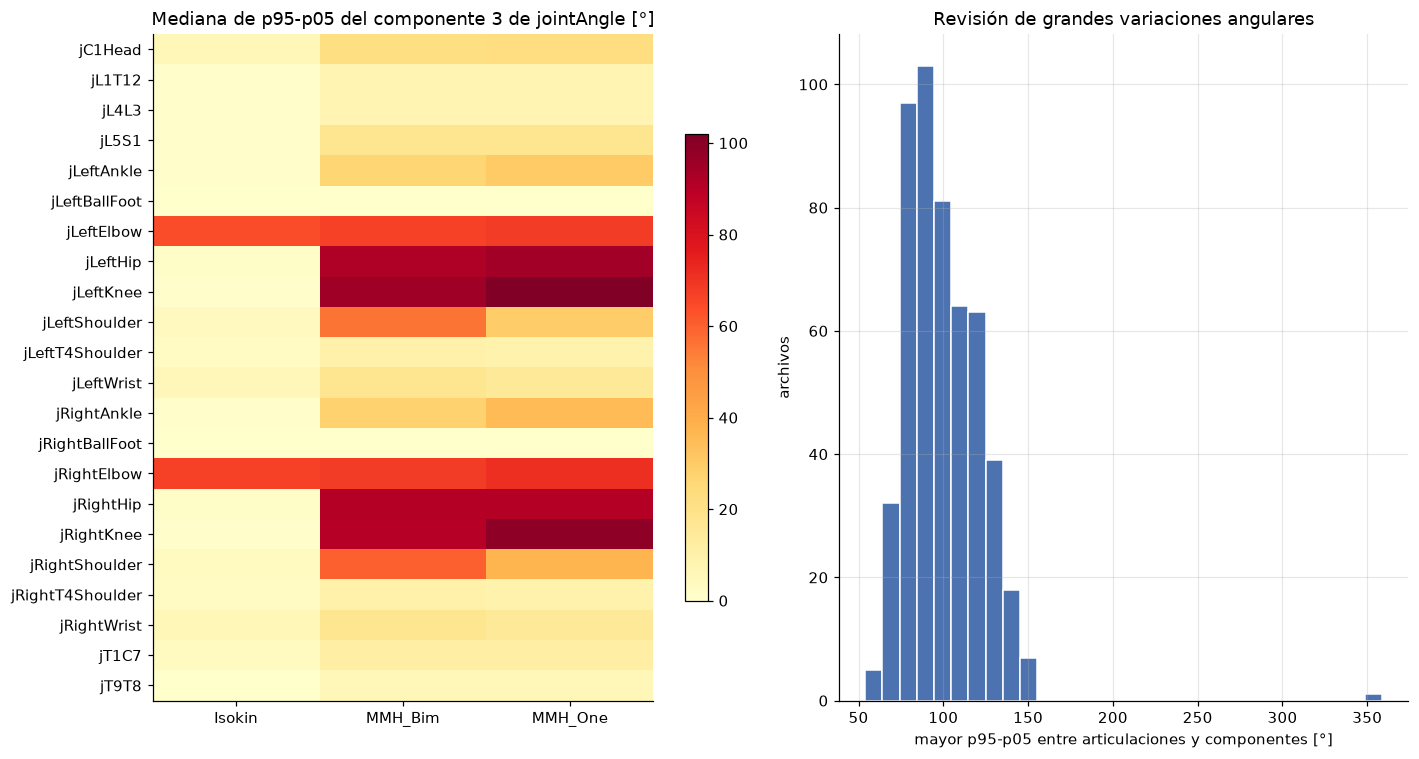

In [39]:
# Conservar el componente 3 para comparar con el ejemplo original; guardar los 3 en caché
mv_joint = mv_joint_stats.merge(mocap[["file", "subject", "task", "side", "load_kg", "condition"]], on="file", validate="many_to_one")
mv_joint_good = mv_joint[~mv_joint.file.isin(BAD_MV_SIGNAL_FILES)]
joint_spread = mv_joint_good[mv_joint_good.component == 3].pivot_table(index="joint", columns="task", values="spread_deg", aggfunc="median")
fig, axes = plt.subplots(1, 2, figsize=(13, 7), gridspec_kw={"width_ratios": [1.1, 1]})
im = axes[0].imshow(joint_spread, aspect="auto", cmap="YlOrRd")
axes[0].set(xticks=range(len(joint_spread.columns)), xticklabels=joint_spread.columns,
            yticks=range(len(joint_spread)), yticklabels=joint_spread.index,
            title="Mediana de p95-p05 del componente 3 de jointAngle [°]")
axes[0].grid(False)
fig.colorbar(im, ax=axes[0], shrink=0.7)
spread_per_file = mv_joint_good.groupby("file").spread_deg.max().sort_values(ascending=False)
axes[1].hist(spread_per_file, bins=30, color="#4c72b0", edgecolor="white")
axes[1].set(xlabel="mayor p95-p05 entre articulaciones y componentes [°]", ylabel="archivos", title="Revisión de grandes variaciones angulares")
fig.tight_layout()
display(spread_per_file.head(8).rename("max_spread_deg").to_frame().round(1))

Hay **14 intervalos de 6 ms en 7 archivos**, por encima de los 4–5 ms esperados al redondear una base temporal de 240 Hz. Ambos campos de tiempo muestran estos intervalos, pero todos los índices de frame son consecutivos; por ello, se consideran irregularidades temporales y no una prueba de pérdida de frames. Los siete archivos marcados se excluyen, de forma conservadora, de las comparaciones de características de movimiento. Después de las exclusiones por anotaciones quedan 508 grabaciones y 8,196 segmentos etiquetados.

En los **7,121,812 frames normales** (8.24 horas sobre la base temporal nominal), los campos revisados no presentan arreglos faltantes, dimensiones incorrectas ni valores no finitos. Ninguna grabación queda marcada por las comprobaciones de índices de frame, normas de cuaterniones o valores de contacto. El mayor error de norma de cuaternión es 9.8e-07.

Estas comprobaciones describen las señales numéricas exportadas. Las coordenadas finitas y los cuaterniones normalizados no establecen la exactitud anatómica ni descartan deriva inercial, errores de calibración o perturbaciones magnéticas. Los campos de sensores solo se inventariaron; las conclusiones sobre valores faltantes y finitos se limitan a los cuatro campos revisados.

Hay dos variantes de exportación: los sujetos 1, 11 y 13 tienen cuatro ternas de ángulos ergonómicos y no incluyen `jointAngleErgoXZY`; los demás tienen seis ternas y el campo XZY adicional. Los cuatro campos revisados tienen las mismas dimensiones en ambas variantes. Por ello, los campos opcionales deben seleccionarse por nombre y comprobarse antes de concatenar grabaciones.

La amplitud de variación angular resume diferencias de movimiento entre tareas. No representa un límite fisiológico: los ángulos de Euler pueden presentar saltos por periodicidad cerca de ±180° y su interpretación depende de la articulación y de la secuencia de rotación. Se muestran las mayores variaciones para inspección, en lugar de eliminarlas mediante un umbral angular arbitrario.


### 9.5. Ensayos de ejemplo con sombreado de actividad propio de MVNX

Los ejemplos bimanual e isocinético usan el mismo sujeto, carga y condición que la sección 7. Se grafican el componente angular 3 de codos y rodillas y las alturas de manos y pelvis frente al tiempo relativo MVNX, con sombreado de actividad tomado de `Labels 2/`. En estas figuras no se aplica ningún desfase del reloj sEMG.


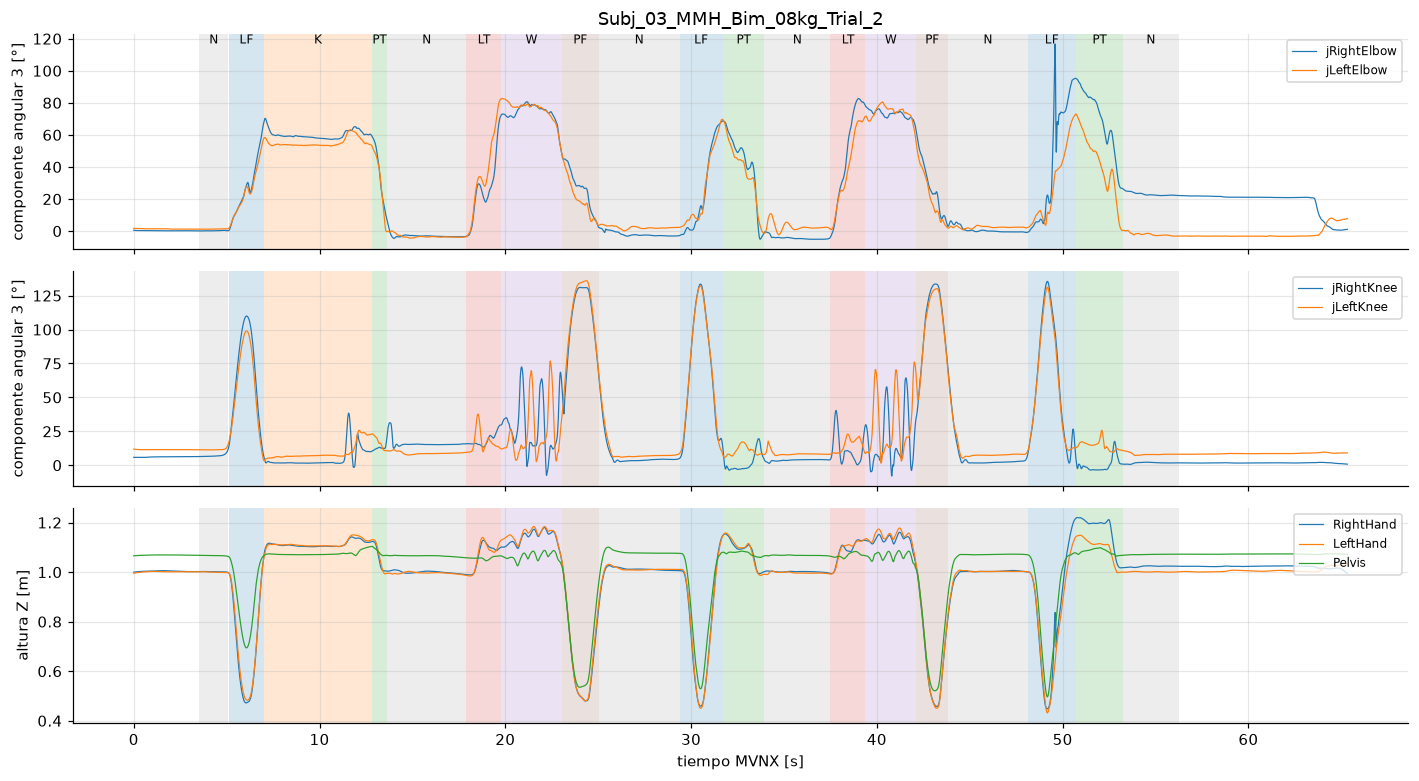

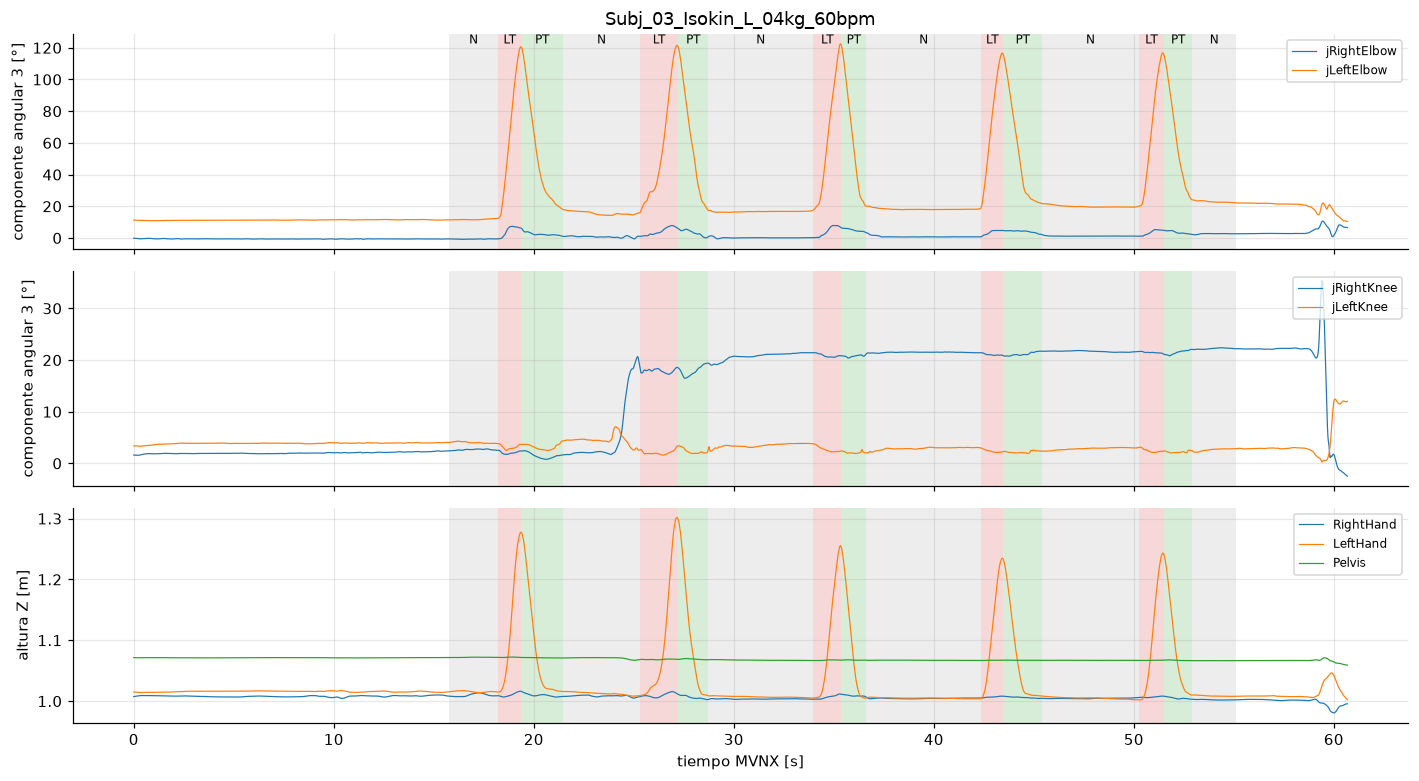

In [40]:
mocap_by_file = mocap.set_index("file")


def plot_mvnx_trial(file):
    row = mocap_by_file.loc[file]
    header = read_mvnx_header(row.path)
    data, _ = read_mvnx_recording(row.path, header)
    angles = data["jointAngle"].reshape(-1, len(header["joints"]), 3)
    positions = data["position"].reshape(-1, len(header["segments"]), 3)
    ji, si = {n: i for i, n in enumerate(header["joints"])}, {n: i for i, n in enumerate(header["segments"])}
    tt = (data["time_ms"] - data["time_ms"][0]) / 1000
    fig, axes = plt.subplots(3, 1, figsize=(13, 7.2), sharex=True)
    for name in ("jRightElbow", "jLeftElbow"):
        axes[0].plot(tt, angles[:, ji[name], 2], lw=0.8, label=name)
    for name in ("jRightKnee", "jLeftKnee"):
        axes[1].plot(tt, angles[:, ji[name], 2], lw=0.8, label=name)
    for name in ("RightHand", "LeftHand", "Pelvis"):
        axes[2].plot(tt, positions[:, si[name], 2], lw=0.8, label=name)
    axes[0].set(ylabel="componente angular 3 [°]", title=row.path.stem)
    axes[1].set(ylabel="componente angular 3 [°]")
    axes[2].set(ylabel="altura Z [m]", xlabel="tiempo MVNX [s]")
    for segment in mv_valid.loc[mv_valid.file == file].itertuples():
        s0, s1 = int(segment.start_idx), int(segment.end_idx)
        for ax in axes:
            ax.axvspan(tt[s0], tt[s1], color=LABEL_COLORS[segment.Label], alpha=0.18, lw=0)
        axes[0].text((tt[s0] + tt[s1]) / 2, axes[0].get_ylim()[1], segment.Label, ha="center", va="top", fontsize=8)
    for ax in axes:
        ax.legend(loc="upper right", fontsize=8)
    fig.tight_layout()


plot_mvnx_trial(example.name)
plot_mvnx_trial("Subj_03_Isokin_L_04kg_60bpm.mvnx")

Los trazos de movimiento aportan información que las envolventes sEMG no proporcionan directamente: la altura de las manos ubica espacialmente las fases de manipulación del objeto, mientras que el movimiento de rodillas y codos describe la postura empleada durante la tarea. Estos ejemplos representan ensayos individuales; la siguiente sección examina las distribuciones del conjunto de grabaciones que cumplen los criterios de inclusión.


### 9.6. Movimiento y actividad

Se reutiliza el enfoque por segmento de la sección 8 y se excluyen los archivos marcados por señal o por anotaciones. Cada segmento aporta una media, independientemente de su duración. En las tareas unilaterales, las características de mano, codo y rodilla usan el lado L/R de la tarea; en las bimanuales se promedian ambos lados. La velocidad de la pelvis se deriva de posiciones consecutivas y de su diferencia real de tiempo.


8196 segmentos de 508 grabaciones de movimiento


,elbow_c3_deg,knee_c3_deg,hand_z_m,pelvis_z_m,pelvis_speed_m_s,contact_frac
Label,,,,,,
N,5.385,2.070,0.945,1.007,0.011,0.734
LF,28.038,55.843,0.702,0.858,0.417,0.640
K,74.997,2.844,1.142,1.005,0.022,0.717
PT,42.601,3.235,1.026,1.007,0.018,0.676
LT,47.807,3.231,1.048,1.009,0.015,0.692
W,69.705,22.369,1.070,0.988,0.758,0.358
PF,22.930,64.588,0.651,0.803,0.337,0.622


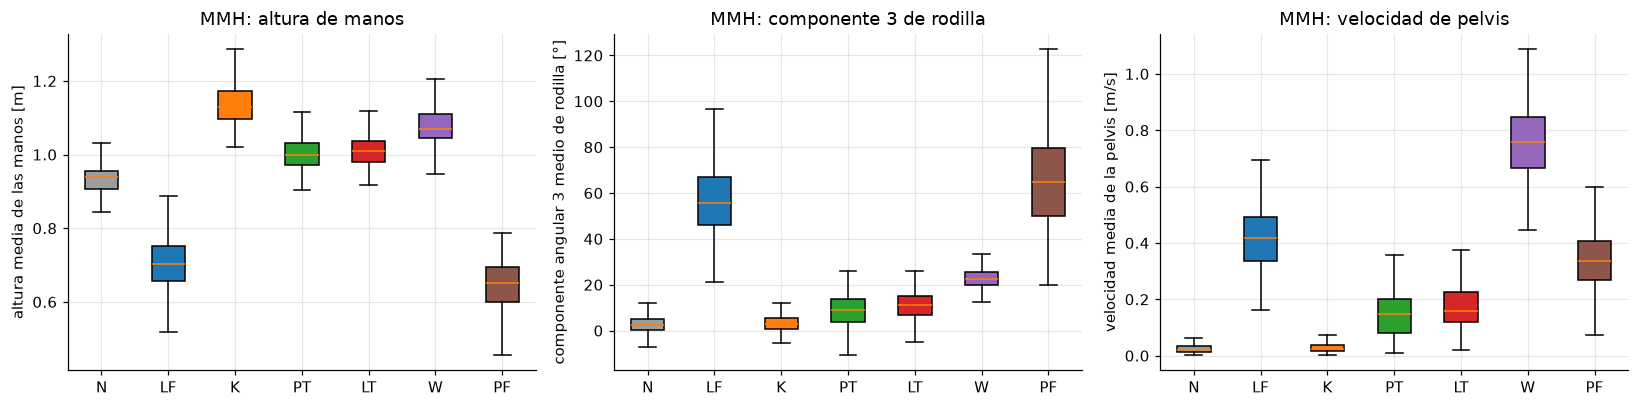

In [41]:
MV_FEATURES = ["elbow_c3_deg", "knee_c3_deg", "hand_z_m", "pelvis_z_m", "pelvis_speed_m_s", "contact_frac"]
mv_seg = mv_seg_stats.merge(mocap[["file", "subject", "task", "side", "load_kg", "condition"]], on="file", validate="many_to_one")
mv_seg = mv_seg[~mv_seg.file.isin(BAD_MV_SIGNAL_FILES | BAD_MV_LABEL_FILES)].copy()
assert len(mv_seg) == len(mv_valid[~mv_valid.file.isin(BAD_MV_SIGNAL_FILES)])
assert np.isfinite(mv_seg[MV_FEATURES]).all().all()
print(f"{len(mv_seg)} segmentos de {mv_seg.file.nunique()} grabaciones de movimiento")
display(mv_seg.groupby("Label")[MV_FEATURES].median().reindex(LABEL_ORDER).round(3))

# MMH incluye las siete clases; Isokin se analiza por separado porque sigue otro protocolo
mv_mmh = mv_seg[mv_seg.task.str.startswith("MMH")]
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
for ax, feature, ylabel in zip(axes, ["hand_z_m", "knee_c3_deg", "pelvis_speed_m_s"],
                             ["altura media de las manos [m]", "componente angular 3 medio de rodilla [°]", "velocidad media de la pelvis [m/s]"]):
    bp = ax.boxplot([mv_mmh.loc[mv_mmh.Label == l, feature] for l in LABEL_ORDER],
                    tick_labels=LABEL_ORDER, patch_artist=True, showfliers=False)
    for patch, label in zip(bp["boxes"], LABEL_ORDER):
        patch.set_facecolor(LABEL_COLORS[label])
    ax.set(ylabel=ylabel, title="MMH: " + {"hand_z_m": "altura de manos", "knee_c3_deg": "componente 3 de rodilla", "pelvis_speed_m_s": "velocidad de pelvis"}[feature])
fig.tight_layout()

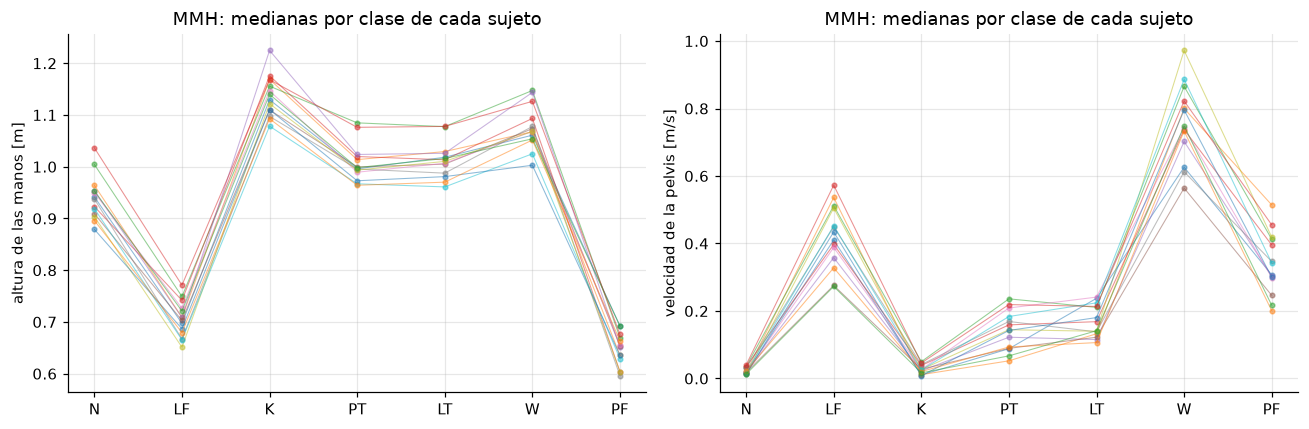

In [42]:
# Las medianas de clase por sujeto dan el mismo peso a cada sujeto; los segmentos son observaciones repetidas
mv_subject_class = mv_mmh.groupby(["subject", "Label"])[MV_FEATURES].median().reset_index()
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, feature, ylabel in zip(axes, ["hand_z_m", "pelvis_speed_m_s"], ["altura de las manos [m]", "velocidad de la pelvis [m/s]"]):
    for subject, g in mv_subject_class.groupby("subject"):
        ax.plot(range(len(LABEL_ORDER)), g.set_index("Label")[feature].reindex(LABEL_ORDER),
                marker="o", ms=3, lw=0.7, alpha=0.5)
    ax.set(xticks=range(len(LABEL_ORDER)), xticklabels=LABEL_ORDER, ylabel=ylabel,
           title="MMH: medianas por clase de cada sujeto")
fig.tight_layout()

En los resúmenes de segmentos MMH, la mediana de la velocidad de la pelvis es 0.758 m/s durante `W` y 0.021 m/s durante `N`. La mediana de la altura de las manos es 0.70 m para `LF` y 1.01 m para `LT`. Estas comparaciones describen promedios de segmentos, no los puntos iniciales o finales de movimientos individuales.

Estas distribuciones son comparaciones descriptivas, no evidencia de la exactitud de un clasificador. Los segmentos del mismo sujeto están correlacionados y el protocolo de la tarea condiciona las actividades presentes. La altura también depende de la antropometría y de la referencia de la grabación. Las gráficas por sujeto ayudan a distinguir un patrón de clase consistente de un efecto dominado por pocos sujetos; la evaluación debe seguir separándose por sujeto, como se explica en la sección 3.


### 9.7. Relación con sEMG y sincronización

Los ensayos se emparejan por sujeto, tarea, carga, condición y lado. El único registro MVNX bimanual se empareja con los registros sEMG de ambos brazos. Primero se comparan los relojes de las grabaciones y después los eventos anotados correspondientes. Las etiquetas propias de MVNX permiten un análisis exclusivo del movimiento, pero **la coincidencia de nombres de actividad no establece sincronización a nivel de muestra**.


643 pares sEMG-MVNX (517 grabaciones MVNX distintas)
Ensayos sEMG sin pareja: 0
Ensayos MVNX sin pareja: 0


,clock_offset_s,duration_diff_s
count,643.00,643.00
mean,3596.78,12.01
std,5.33,8.12
min,3578.32,-35.67
25%,3594.35,10.25
50%,3596.48,12.68
75%,3597.56,16.23
max,3633.05,34.43


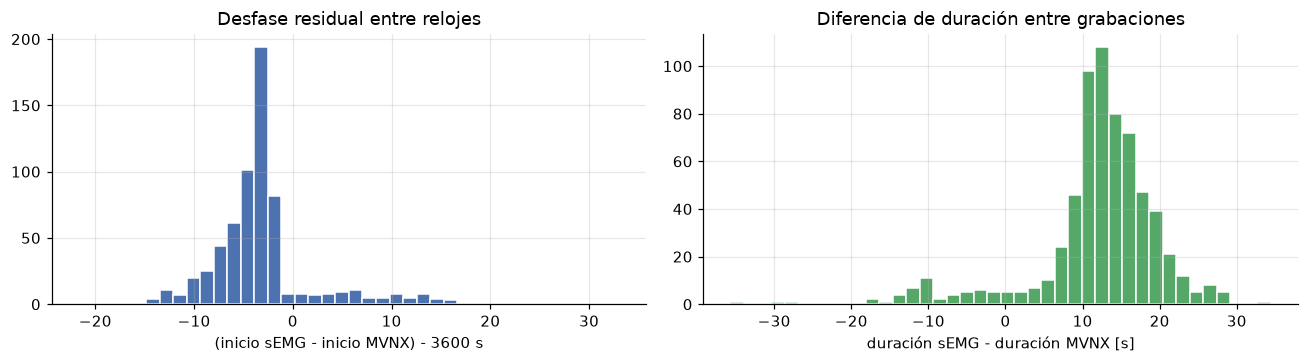

In [43]:
keys = ["subject", "task", "load_kg", "condition"]
pairs = mocap.merge(trials, on=keys, suffixes=("_mv", "_emg"))
pairs = pairs[pairs.side_mv.isna() | (pairs.side_mv == pairs.side_emg)].copy()
assert not pairs.file_emg.duplicated().any(), "Un ensayo sEMG tiene varias grabaciones de movimiento correspondientes"
print(f"{len(pairs)} pares sEMG-MVNX ({pairs.file_mv.nunique()} grabaciones MVNX distintas)")
print("Ensayos sEMG sin pareja:", len(set(trials.file) - set(pairs.file_emg)))
print("Ensayos MVNX sin pareja:", len(set(mocap.file) - set(pairs.file_mv)))
pairs["clock_offset_s"] = (pairs.t0_ms - pairs.ms0) / 1000
pairs["duration_diff_s"] = pairs.duration_s_emg - pairs.duration_s_mv
display(pairs[["clock_offset_s", "duration_diff_s"]].describe().round(2))

fig, axes = plt.subplots(1, 2, figsize=(12, 3.4))
axes[0].hist(pairs.clock_offset_s - 3600, bins=40, color="#4c72b0", edgecolor="white")
axes[0].set(xlabel="(inicio sEMG - inicio MVNX) - 3600 s", title="Desfase residual entre relojes")
axes[1].hist(pairs.duration_diff_s, bins=40, color="#55a868", edgecolor="white")
axes[1].set(xlabel="duración sEMG - duración MVNX [s]", title="Diferencia de duración entre grabaciones")
fig.tight_layout()

Misma secuencia ordenada de actividad: 641 / 641 pares que cumplen los criterios


,file_emg,file_mv


,event_pairs,offset_s,residual_p95_s,median_abs_duration_delta_s
count,641.000,641.000,641.000,641.000
mean,16.512,11.829,0.023,0.005
std,4.265,5.438,0.053,0.006
min,4.000,-31.465,0.000,0.000
25%,16.000,10.359,0.001,0.002
50%,19.000,12.000,0.001,0.002
75%,19.000,14.539,0.001,0.003
max,19.000,31.550,0.253,0.027


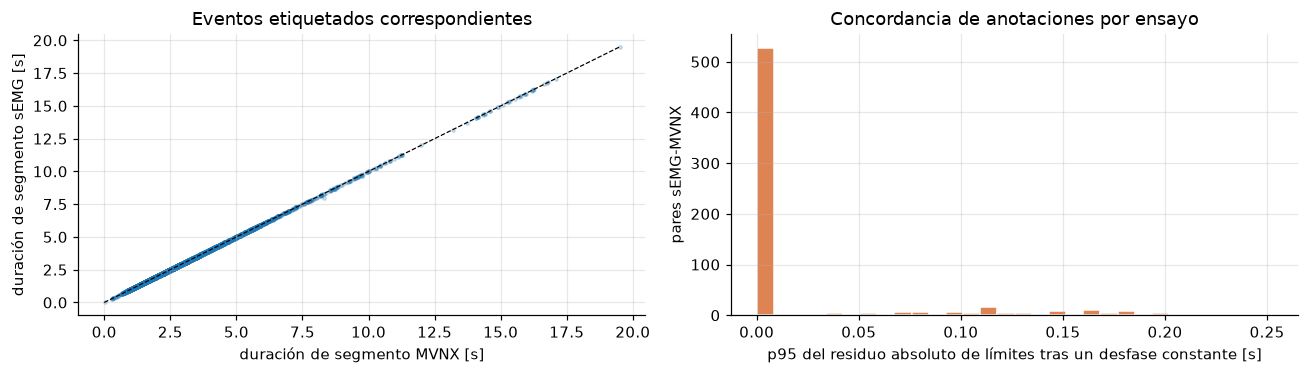

In [44]:
# Comparar anotaciones solo cuando coinciden las secuencias ordenadas completas
emg_sequences = valid.groupby("file").Label.apply(tuple)
mv_sequences = mv_valid.groupby("file").Label.apply(tuple)
eligible_pairs = pairs[~pairs.file_emg.isin(BAD_LABEL_FILES) & ~pairs.file_mv.isin(BAD_MV_LABEL_FILES)].copy()
eligible_pairs["same_sequence"] = [emg_sequences.get(e) == mv_sequences.get(m) for e, m in zip(eligible_pairs.file_emg, eligible_pairs.file_mv)]
print(f"Misma secuencia ordenada de actividad: {eligible_pairs.same_sequence.sum()} / {len(eligible_pairs)} pares que cumplen los criterios")
display(eligible_pairs.loc[~eligible_pairs.same_sequence, ["file_emg", "file_mv"]].head(10))

same_pairs = eligible_pairs[eligible_pairs.same_sequence][["file_emg", "file_mv"]]
events = same_pairs.merge(valid[["file", "seg", "Label", "Start_Frame", "seg_s", "fs_hz"]],
                         left_on="file_emg", right_on="file", validate="one_to_many").drop(columns="file")
events = events.merge(mv_valid[["file", "seg", "Label", "start_idx", "seg_s", "frame_rate"]],
                      left_on=["file_mv", "seg", "Label"], right_on=["file", "seg", "Label"],
                      suffixes=("_emg", "_mv"), validate="many_to_one")
events["start_emg_s"] = events.Start_Frame / events.fs_hz
events["start_mv_s"] = events.start_idx / events.frame_rate
events["event_offset_s"] = events.start_emg_s - events.start_mv_s
# Restar el desfase mediano de cada par para identificar desacuerdos que no explica un desplazamiento constante
events["residual_s"] = events.event_offset_s - events.groupby("file_emg").event_offset_s.transform("median")
events["duration_delta_s"] = events.seg_s_emg - events.seg_s_mv
alignment = events.groupby("file_emg").agg(event_pairs=("seg", "size"), offset_s=("event_offset_s", "median"),
    residual_p95_s=("residual_s", lambda s: s.abs().quantile(.95)),
    median_abs_duration_delta_s=("duration_delta_s", lambda s: s.abs().median()))
display(alignment.describe().round(3))

fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
axes[0].scatter(events.seg_s_mv, events.seg_s_emg, s=5, alpha=0.2)
limit = max(events.seg_s_mv.max(), events.seg_s_emg.max())
axes[0].plot([0, limit], [0, limit], "k--", lw=0.8)
axes[0].set(xlabel="duración de segmento MVNX [s]", ylabel="duración de segmento sEMG [s]", title="Eventos etiquetados correspondientes")
axes[1].hist(alignment.residual_p95_s, bins=30, color="#dd8452", edgecolor="white")
axes[1].set(xlabel="p95 del residuo absoluto de límites tras un desfase constante [s]", ylabel="pares sEMG-MVNX", title="Concordancia de anotaciones por ensayo")
fig.tight_layout()

Los relojes difieren aproximadamente una hora, con un desfase residual que depende del ensayo y distintas duraciones de grabación. Una configuración de zona horaria podría explicar la hora de diferencia, pero los archivos no permiten confirmarlo. Por tanto, restar 3600 s a todas las marcas de tiempo no basta para establecer la alineación.

La comparación de eventos usa la **secuencia ordenada completa**, no solo el código de una clase, porque las actividades se repiten dentro del ensayo. La mediana del desfase de eventos de cada par es una estimación exploratoria; los residuos muestran si un desplazamiento constante explica los límites de las etiquetas sobre la base temporal nominal MVNX. Las diferencias entre la frecuencia nominal y las marcas de tiempo descritas en la sección 9.2 también pueden contribuir al desacuerdo con las señales reales. La coincidencia de límites puede reflejar diferencias de anotación y no verifica las señales crudas. Antes del modelado multimodal se debe validar una correspondencia temporal por ensayo con eventos de movimiento visibles y las marcas de tiempo reales de los frames, remuestrear sobre una base temporal común y mantener ambos brazos sEMG y su MVNX compartido en la misma partición por sujeto. Este EDA no aplica ninguna alineación a las señales registradas.


# 10. Resumen de hallazgos

### Contenido del conjunto de datos

- **14 sujetos** (12 hombres / 2 mujeres, de 25 a 38 años), con 37 ensayos previstos por sujeto: 16 isocinéticos, 9 MMH bimanuales y 12 MMH unilaterales. El sujeto 12 es el único incompleto: falta `Isokin_L_02kg_80bpm` en ambas modalidades.
- **sEMG**: 643 CSV de ensayos + 36 CSV MVC, 8 canales y 27.7 millones de muestras (13.2 h). Los ensayos bimanuales tienen un archivo por brazo.
- **Captura de movimiento**: 517 MVNX (~57 GB), Xsens a 240 Hz, 23 segmentos / 17 IMU / 22 articulaciones. La sección 9 recorre todos los frames normales, inventaría los campos exportados y revisa cuatro campos principales.
- **Etiquetas propias de MVNX**: 517 CSV en `Labels 2/`, con 8,337 segmentos antes de las exclusiones de calidad. Usan sus propios índices de frame y permiten analizar la actividad únicamente con movimiento.
- **Etiquetas sEMG**: 10,612 segmentos en 7 clases y ~8.7 h etiquetadas. `N` representa el 43 % del tiempo etiquetado; los ensayos isocinéticos solo contienen `N`, `LT`, `PT` y, en la condición estática, `K`.

### Aspectos que deben atenderse antes del modelado

| Problema | Evidencia | Tratamiento sugerido |
|---|---|---|
| La frecuencia sEMG varía por archivo (367–1006 Hz) | Sección 4 | Calcular la frecuencia por archivo y remuestrear, o definir ventanas por tiempo |
| Las etiquetas sEMG cubren solo ~2/3 de cada grabación | Sección 5 | Descartar muestras sin etiqueta o justificar su asignación a `N` |
| 2 archivos de etiquetas inconsistentes, con segmentos superpuestos o vacíos | Sección 5: `Subj_02_MMH_One_R_02kg_Trial_2`, `Subj_05_Isokin_L_04kg_80bpm` | Corregir o excluir |
| 3 archivos sEMG con fallas en los canales 7–8 (hasta ~2 V) | Sección 6: sujeto 7, `MMH_Bim_R` de 08 kg, ensayo 3, y de 12 kg, ensayos 1–2 | Excluir los archivos o enmascarar los canales; otros 5 archivos del sujeto 7 son ruidosos |
| `Norm_RMS` no está acotada al 100 %MVC: 434 de 640 ensayos lo superan en p99 | Sección 6 | Interpretar %MVC como escala por sujeto |
| La señal cruda presenta desplazamiento, deriva y alta correlación entre canales | Secciones 6–7 | Usar `Norm_RMS` o filtrar la señal cruda como en `Process.m` |
| No se documenta la correspondencia canal → músculo | Sección 7 | Confirmar con el artículo |
| Las etiquetas MVNX contienen intervalos invertidos o superpuestos | Sección 9.3 | Revisar los archivos marcados y excluirlos de los resúmenes de actividad |
| 14 intervalos temporales MVNX de 6 ms en 7 archivos, con índices de frame consecutivos | Sección 9.4 | Revisar la variación temporal; estos archivos se excluyen de forma conservadora de las comparaciones de características |
| La frecuencia nominal MVNX es 240 Hz; la efectiva alcanza 241.83 Hz | Sección 9.2 | Usar las marcas de tiempo reales para el análisis temporal y la sincronización |
| Dos variantes MVNX tienen distintos campos ergonómicos opcionales | Sección 9.4 | Inspeccionar los campos disponibles antes de concatenar grabaciones |
| El origen de los índices de etiquetas MVNX no es explícito en los CSV | Sección 9.3 | Verificar el supuesto de índices desde cero antes de preparar ventanas de entrenamiento |
| Los componentes de Euler y las coordenadas globales MVNX dependen de sus convenciones de referencia | Secciones 9.1 y 9.4 | Conservar el orden articulación / componente y revisar la periodicidad angular y la referencia espacial |
| sEMG y MVNX tienen relojes diferentes (~1 h de desfase ± segundos; sEMG dura ~12 s más) | Sección 9.7 | Validar una correspondencia temporal por ensayo antes de fusionar modalidades; usar las etiquetas MVNX para el análisis exclusivo de movimiento |

### Lo que sugieren los datos

- **Reposo y actividad** se distinguen claramente con sEMG (`N` ≈ 8–13 %MVC frente a 30–55 % para las clases activas), pero las clases activas se superponen considerablemente. Distinguir `LF`/`LT`/`PT`/`PF` requiere explorar los datos de movimiento y el contexto temporal; la secuencia del ensayo es fija: `N → LF → (K) → PT → N → LT → W → PF → ...`.
- **La carga se refleja en la sEMG**: la amplitud crece de forma monótona con la carga en cada clase activa, aproximadamente 3× de 2 a 12 kg para `K` y `W`.
- **Cohorte pequeña**: con 14 sujetos, la evaluación debe separarse por sujeto, dejando uno fuera en cada iteración, y considerar las diferencias de amplitud cruda entre sujetos (0.2–2 mV).
- **Desbalance de clases**: `N` representa el 43 % del tiempo y las demás clases entre el 7 y el 15 % cada una; `K` solo aparece una vez por ensayo MMH.

### Aportaciones de la ampliación MVNX

- **Características de movimiento**: las medias por segmento de alturas de manos/pelvis, componente angular 3 de codos/rodillas, velocidad de pelvis y contactos de pies complementan los resúmenes de amplitud sEMG. Las comparaciones por clase usan anotaciones propias de MVNX y muestran la variación entre sujetos.
- **Alcance explícito de calidad**: se revisan dimensiones, valores finitos, normas de cuaterniones y valores de contacto en los campos principales seleccionados; la validez numérica no establece la exactitud biomecánica.
- **Recorrido reproducible**: el análisis completo MVNX se guarda en caché junto con un registro de los archivos de origen, conservando el flujo de trabajo y los ejemplos sEMG.
- **Evidencia para sincronización**: se distinguen los desfases entre relojes de la coincidencia entre eventos etiquetados repetidos; la fusión a nivel de muestra sigue siendo una tarea de preprocesamiento.


# 11. Glosario

* `Xsens MVN`: Sistema de captura de movimiento utilizado en el conjunto de datos y origen de los archivos `.mvnx`. El sujeto lleva unidades de medición inercial (IMU) distribuidas por el cuerpo; cada una combina acelerómetro, giroscopio y magnetómetro para registrar el movimiento.

* `sEMG` (electromiografía de superficie): Registro no invasivo de la actividad eléctrica que generan los músculos al contraerse o relajarse.

* `Isocinético` (`Isokin`): Modalidad de movimiento en la que se mantiene constante la velocidad; es el nombre de una de las tareas del conjunto.

* `MMH` (manipulación manual de materiales): Actividades en las que una persona emplea su fuerza para levantar, empujar, jalar o transportar objetos.

* `MVC` (contracción voluntaria máxima): Valor de referencia por sujeto, lado y canal. Se calcula por separado con los ensayos `MVC_*` y sus archivos `_range.csv`, y permite comparar las señales normalizadas.

* `Raw_V_i` (voltios): Señal cruda del electrodo, tal como la registró el sensor. Oscila entre valores positivos y negativos y contiene ruido.

* `Norm_V_i` (%MVC): Señal filtrada, rectificada (valor absoluto) y expresada como porcentaje de la contracción máxima de referencia.

* `Norm_RMS_i` (%MVC): Envolvente RMS de la señal filtrada; es una curva suave que resume el nivel de activación muscular.

* `Canal`: Cada una de las 8 señales EMG registradas simultáneamente. Los canales se analizan por separado; la correspondencia exacta entre canal y músculo debe confirmarse en la documentación del conjunto.

* `MVNX`: Formato XML de exportación de Xsens. Incluye el modelo corporal, metadatos y señales de movimiento; los frames `normal` corresponden a muestras de la grabación.

* `Labels 2/`: Anotaciones de actividad cuyos límites se expresan en frames MVNX. No deben usarse directamente como índices de las señales sEMG.

* `Cuaternión`: Representación de la orientación con cuatro componentes. Su norma debe ser cercana a uno; esto comprueba consistencia numérica, no la exactitud de la postura.

* `jointAngle`: Tres componentes angulares por articulación, expresadas en grados. El orden y la secuencia de rotación forman parte de la definición de la señal.

* `Frame de calibración`: Pose de referencia del modelo (`identity`, `tpose`, `tpose-isb`). Se excluye del conteo de muestras y de las etiquetas de actividad.

* `Sincronización`: Correspondencia temporal entre las muestras de dos sistemas. Compartir un ensayo o una etiqueta no garantiza que sus muestras estén alineadas.
